# Eda 데이터 탐색

## 데이터 로드

- `ann_df`: bbox 한 개당 한 행 (이미지 메타 + 약 정보 + bbox)
- `img_df`: train 이미지 한 장당 한 행 (촬영 정보 + 객체 수)
- `cat_df`: category_id ↔ 약 이름
- `test_files`: test 이미지 파일명 목록

In [1]:
import json
from pathlib import Path

import pandas as pd

DATA_DIR = Path("../data")
RAW_DIR = DATA_DIR / "raw"  # 받은 원본 그대로 (수정하지 않음)
PROCESSED_DIR = DATA_DIR / "processed"  # 직접 만들거나 고친 결과물
# 압축을 푼 위치에 따라 sprint_ai_project1_data 폴더가 한 단계 더 있을 수 있다
if (RAW_DIR / "sprint_ai_project1_data").exists():
    RAW_DIR = RAW_DIR / "sprint_ai_project1_data"

TRAIN_IMG_DIR = RAW_DIR / "train_images"
TEST_IMG_DIR = RAW_DIR / "test_images"
ANN_DIR = RAW_DIR / "train_annotations"

IMG_EXTS = {".png", ".jpg", ".jpeg"}
# 이미지 단위로 같은 값을 갖는 촬영 정보. 나머지 필드(drug_N, dl_name 등)는 알약마다 다르다
IMAGE_COLS = [
    "file_name",
    "width",
    "height",
    "back_color",
    "light_color",
    "camera_la",
    "camera_lo",
    "size",
]


def list_images(folder: Path) -> list[Path]:
    """Zone.Identifier 등을 빼고 이미지 파일만 반환한다."""
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS)


def load_annotations(ann_dir: Path) -> pd.DataFrame:
    """json 하나 = 이미지 한 장 속 알약 한 종류. 모든 json을 bbox 한 개당 한 행으로 펼친다."""
    rows = []
    for path in sorted(ann_dir.rglob("*.json")):
        with open(path, encoding="utf-8") as f:
            data = json.load(f)
        images = {img["id"]: img for img in data["images"]}
        for ann in data["annotations"]:
            x, y, w, h = ann["bbox"]
            rows.append(
                {
                    **images[ann["image_id"]],
                    "category_id": ann["category_id"],
                    "x": x,
                    "y": y,
                    "w": w,
                    "h": h,
                    "area": ann["area"],
                    "json_path": str(path),
                }
            )
    return pd.DataFrame(rows).drop(columns=["id"])


ann_df = load_annotations(ANN_DIR)

# 이미지 단위 테이블: 어노테이션이 없는 이미지도 포함
img_df = pd.DataFrame({"file_name": [p.name for p in list_images(TRAIN_IMG_DIR)]})
img_meta = ann_df[IMAGE_COLS].drop_duplicates("file_name")
img_df = img_df.merge(img_meta, on="file_name", how="left")
img_df["n_objects"] = (
    img_df["file_name"].map(ann_df["file_name"].value_counts()).fillna(0).astype(int)
)

# 클래스 테이블: category_id ↔ 약 이름
cat_df = (
    ann_df[["category_id", "dl_name", "dl_name_en"]]
    .drop_duplicates("category_id")
    .sort_values("category_id")
    .reset_index(drop=True)
)

test_files = [p.name for p in list_images(TEST_IMG_DIR)]

print("train 이미지:", len(img_df), "/ test 이미지:", len(test_files))
print("bbox 수:", len(ann_df), "/ 클래스 수:", len(cat_df))
print("어노테이션 없는 train 이미지:", (img_df["n_objects"] == 0).sum())
ann_df.head()

train 이미지: 232 / test 이미지: 842
bbox 수: 763 / 클래스 수: 56
어노테이션 없는 train 이미지: 0


,file_name,width,height,imgfile,drug_N,drug_S,back_color,drug_dir,light_color,camera_la,...,mark_code_front,mark_code_back,change_date,category_id,x,y,w,h,area,json_path
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,70,...,,,20160825,1900,644,845,189,190,35910,../data/raw/train_annotations/K-001900-016548-...
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,75,...,,,20160825,1900,148,241,181,181,32761,../data/raw/train_annotations/K-001900-016548-...
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,90,...,,,20160825,1900,167,248,184,182,33488,../data/raw/train_annotations/K-001900-016548-...
3,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,K-016548,정상알약,연회색 배경,앞면,주백색,70,...,NaN,NaN,NaN,16548,144,799,239,239,57121,../data/raw/train_annotations/K-001900-016548-...
4,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,K-016548,정상알약,연회색 배경,앞면,주백색,75,...,NaN,NaN,NaN,16548,578,222,233,226,52658,../data/raw/train_annotations/K-001900-016548-...


## 데이터 정의서

`ann_df` 기준, bbox(알약) 1개당 1행입니다. 전체 763행, 56개 컬럼입니다.

### 이미지 정보

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| file_name | str | 이미지 파일명. 이미지 단위의 키로 사용됩니다. 앞부분(`K-003351-018357-036637`)에 사진에 찍힌 약 코드가 들어 있습니다. |
| imgfile | str | 이미지 파일명. `file_name`과 같은 값입니다. |
| width | int | 이미지 너비(px). 전부 976입니다. |
| height | int | 이미지 높이(px). 전부 1280입니다. |
| json_path | str | 이 행을 읽어 온 어노테이션 json 파일 경로입니다. |

### 촬영 조건

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| back_color | str | 배경색. 전부 `연회색 배경`입니다. |
| light_color | str | 조명 색. 전부 `주백색`입니다. |
| camera_la | int | 카메라 촬영 각도(위도). 70, 75, 90 세 가지입니다. |
| camera_lo | int | 카메라 회전 각도(경도). 전부 0입니다. |
| size | int | 촬영 크기 설정값. 전부 200입니다. |
| drug_dir | str | 촬영된 알약 면. `앞면` 또는 `뒷면`입니다. |
| drug_S | str | 알약 상태. 전부 `정상알약`입니다. |

### 정답 (타깃)

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| category_id | int | **타깃 변수(클래스)**. 약 종류 코드이며 56종입니다. `drug_N`의 숫자 부분과 같습니다. |
| x | int | **타깃 변수(bbox)**. 박스 왼쪽 위 꼭짓점의 x 좌표(px)입니다. |
| y | int | **타깃 변수(bbox)**. 박스 왼쪽 위 꼭짓점의 y 좌표(px)입니다. |
| w | int | **타깃 변수(bbox)**. 박스 너비(px)입니다. |
| h | int | **타깃 변수(bbox)**. 박스 높이(px)입니다. |
| area | int | 박스 넓이(px²). `w × h`와 같습니다. |

### 약 식별 코드

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| drug_N | str | 약 코드(예: `K-003351`). `category_id`에 `K-`를 붙인 형태입니다. |
| dl_mapping_code | str | 약 매핑 코드. `drug_N`과 같은 값입니다. |
| dl_idx | str | 약 코드의 숫자 부분(예: `3351`)입니다. (이 부분은 일단 눈여겨 보자)|
| item_seq | int | 식약처 품목기준코드입니다. |
| di_edi_code | str | 건강보험 EDI 코드. 여러 개면 쉼표로 구분합니다. |

### 약 기본 정보

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| dl_name | str | 약 이름(한글)입니다. |
| dl_name_en | str | 약 이름(영문). 14행이 빈 문자열입니다. |
| dl_material | str | 주성분(한글). 성분이 여러 개면 `\|`로 구분합니다. 9행이 빈 문자열입니다. |
| dl_material_en | str | 주성분(영문)입니다. |
| dl_company | str | 제약회사(한글)입니다. |
| dl_company_en | str | 제약회사(영문)입니다. |
| di_company_mf | str | 위탁 제조사(한글). 대부분(637행) 빈 문자열입니다. |
| di_company_mf_en | str | 위탁 제조사(영문). 대부분(724행) 빈 문자열입니다. |
| di_class_no | str | 약효 분류(예: `[02180]동맥경화용제`)입니다. |
| di_etc_otc_code | str | 의약품 구분. `전문의약품` 또는 `일반의약품`입니다. |
| di_item_permit_date | str | 품목 허가일(YYYYMMDD)입니다. |

### 약 외형

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| dl_custom_shape | str | 제형 분류(예: `정제, 저작정`, `경질캡슐제`)입니다. |
| form_code_name | str | 제형 이름(예: `필름코팅정`, `나정`)입니다. |
| drug_shape | str | 알약 모양(예: `원형`, `타원형`, `장방형`)입니다. |
| chart | str | 성상. 알약 생김새를 글로 설명한 것입니다. |
| color_class1 | str | 주 색상입니다. |
| color_class2 | str | 보조 색상. 대부분 빈 문자열입니다. |
| thick | float | 두께(mm). 0.0은 값이 없는 경우입니다. |
| leng_long | float | 장축 길이(mm). 0.0은 값이 없는 경우입니다. |
| leng_short | float | 단축 길이(mm). 0.0은 값이 없는 경우입니다. |
| print_front | str | 앞면 각인 문자(예: `R5`)입니다. |
| print_back | str | 뒷면 각인 문자. `분할선`처럼 적힌 경우도 있습니다. |
| line_front | str | 앞면 분할선. `-`(일자), `+`(십자), 빈 문자열(없음)입니다. |
| line_back | str | 뒷면 분할선. 값은 `line_front`와 같은 방식입니다. |

### 마크 정보

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| mark_code_front_anal | str | 앞면 마크 설명(예: `pfizer`). 대부분 빈 문자열입니다. |
| mark_code_front_img | str | 앞면 마크 이미지 URL. 대부분 빈 문자열입니다. |
| mark_code_back_anal | str | 뒷면 마크 설명. 전부 비어 있습니다. |
| mark_code_back_img | str | 뒷면 마크 이미지 URL. 전부 비어 있습니다. |
| mark_code_front | str | 앞면 마크 코드. 전부 비어 있습니다. |
| mark_code_back | str | 뒷면 마크 코드. 전부 비어 있습니다. |

### 기타

| 컬럼명 | 데이터 타입 | 설명 |
|---|---|---|
| img_key | str | 공공 낱알 이미지 URL입니다. |
| img_regist_ts | str | 낱알 이미지 등록일(YYYYMMDD)입니다. |
| change_date | str | 약 정보 변경일(YYYYMMDD)입니다. |

> 참고: `img_key`, `chart`, `drug_shape`, `print_*`, `color_*`, `line_*`, `mark_*`, `img_regist_ts`, `change_date`, `form_code_name`은 json에 해당 필드가 없는 18행이 결측(NaN)입니다.


## train 데이터 내부에서 정답 박스가 없는 이미지가 있는지 확인(결측치 확인)

파일명 앞부분(`K-003351-018357-036637`)에 사진에 찍힌 약 코드가 들어 있다. 파일명에는 있는데 bbox가 없는 약을 라벨 결측으로 보고, 해당 이미지를 띄워 확인한다.

- 초록 박스: 라벨된 bbox (숫자는 category_id)
- 제목의 `missing`: bbox가 빠진 약 코드

In [ ]:
# 파일명 앞부분(K-003351-018357-036637)에 사진에 찍힌 약 코드가 들어 있다
img_df["drug_codes"] = (
    img_df["file_name"]
    .str.split("_")
    .str[0]
    .str.split("-")
    .str[1:]
    .apply(lambda codes: [int(c) for c in codes])
)
img_df["n_drugs"] = img_df["drug_codes"].str.len()

# 파일명에는 있는데 bbox(category_id)가 없는 약 = 라벨 결측
labeled = ann_df.groupby("file_name")["category_id"].apply(set)
img_df["missing_codes"] = img_df.apply(
    lambda r: [c for c in r["drug_codes"] if c not in labeled.get(r["file_name"], set())], axis=1
)

missing_df = img_df[img_df["missing_codes"].str.len() > 0].reset_index(drop=True)
print("라벨이 빠진 이미지:", len(missing_df), "/", len(img_df))
missing_df[["file_name", "n_drugs", "n_objects", "missing_codes"]]

## 라벨(bbox)이 빠진 이미지 시각화 

In [ ]:
import math

import matplotlib.patches as patches
import matplotlib.pyplot as plt

# 한글 폰트 없이도 깨지지 않도록 영문 약 이름을 쓴다
name_en = dict(zip(cat_df["category_id"], cat_df["dl_name_en"]))


def draw_boxes(ax, file_name):
    """이미지에 라벨된 bbox를 초록색으로 그린다."""
    ax.imshow(plt.imread(TRAIN_IMG_DIR / file_name))
    for r in ann_df[ann_df["file_name"] == file_name].itertuples():
        ax.add_patch(
            patches.Rectangle((r.x, r.y), r.w, r.h, fill=False, edgecolor="lime", linewidth=2)
        )
        ax.text(r.x, r.y - 10, str(r.category_id), color="lime", fontsize=9, weight="bold")
    ax.axis("off")


cols = 4
rows = math.ceil(len(missing_df) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 5.5), squeeze=False)
for ax, r in zip(axes.flat, missing_df.itertuples()):
    draw_boxes(ax, r.file_name)
    missing = "\n".join(f"{c} ({name_en.get(c) or '?'})" for c in r.missing_codes)
    ax.set_title(f"{r.file_name.split('_')[0]}\nmissing: {missing}", fontsize=8, color="red")
for ax in axes.flat[len(missing_df) :]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 데이터를 열어보니 하나의 이미지 안에 정답 박스가 전부 없는 것이 아니라, 하나의 알약에만 정답 박스가 없다.
### 이러한 데이터를 그대로 훈련에 사용되면 발생할 수 있는 문제
1. 빠진 알약을 배경으로 학습.
=> 결과적으로 약을 덜 검출하는 쪽으로, 모델이 미탐 쪽으로 기울 수 있다.
2. 같은 약에 대해 정답이 헷갈린다.
=> 3351(Hytrin)은 다른 사진에서는 "알약"으로 라벨돼 있는데, 이 4장에서는 "배경"으로 취급됩니다. 결과적으로 모델이 해당 약에 대한 확신이 낮아질 수 있다.
3. 이 이미지가 그대로 validation 세트에 들어가면, 모델이 빠진 알약을 맞게 찾아도 오답(false positive)으로 채점됨.
4. 데이터 증강이 문제를 퍼뜨릴 수 있다
박스 없는 알약 조각이 여러 학습 이미지에 섞여 들어가게 됨.

## 트레인 데이터에 알약들의 개수와 분포는 어떻게 될까?

In [ ]:
# 알약(category_id)별 라벨된 bbox 수와 전체 대비 비율
class_counts = (
    ann_df["category_id"]
    .value_counts()
    .rename_axis("category_id")
    .reset_index(name="n_boxes")
    .merge(cat_df, on="category_id", how="left")
)
class_counts["ratio(%)"] = (class_counts["n_boxes"] / class_counts["n_boxes"].sum() * 100).round(2)

print("전체 bbox 수:", class_counts["n_boxes"].sum(), "/ 클래스 수:", len(class_counts))
class_counts[["category_id", "dl_name", "n_boxes", "ratio(%)"]]


### 라벨 결측 약별 비율

| 빠진 약 (category_id) | 약 이름 | 라벨된 박스 | 빠진 박스 | 빠진 비율 |
|---|---|---:|---:|---:|
| 3351 | 일양하이트린정 2mg | 153 | 4 | 약 3% |
| 4543 | Airtal Tab. | 5 | 1 | 약 17% |
| 20014 | Madopar Tab. | 16 | 1 | 약 6% |
| 33880 | Glitin Tab. | 16 | 1 | 약 6% |
| 32310 | (영문명 없음) | 14 | 1 | 약 7% |

> 빠진 비율 = 빠진 박스 ÷ (라벨된 박스 + 빠진 박스)


## 결측치(bbox가 missing) 처리 방안
### 1. 그대로 쓰기
### 2. 빠진 박스 8개를 직접 그려 넣기
### 3. 전부 빼기(그렇게 된다면 멀쩡한 박스 16개도 손실)
### 4. 최소한 이 8장은 validation 세트에서 빼기

## 라벨 결측 보완

### 1. 원본 보존 원칙

- `data/raw/`는 받은 원본 그대로 두고 **절대 수정하지 않는다**. 원본이 곧 백업이므로 따로 복사본을 만들지 않는다.
- 새로 만든 박스는 `data/processed/added_annotations.csv`에만 저장한다.
- 원본 라벨만 쓰고 싶으면 아래 "학습용 어노테이션" 셀에서 `USE_ADDED = False`로 두거나, `reset_added()`로 추가 박스 파일을 지운다.

In [ ]:
ADDED_PATH = PROCESSED_DIR / "added_annotations.csv"  # 새로 추가한 박스만 따로 저장하는 파일
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
print("원본 json 수:", len(list(ANN_DIR.rglob("*.json"))))


def reset_added():
    """추가 박스 파일을 지워 원본 라벨만 남긴다. data/raw는 건드리지 않는다."""
    ADDED_PATH.unlink(missing_ok=True)
    print("추가 박스 파일 삭제 완료: 원본 라벨만 사용")

### 2. 알약 위치 자동 검출

배경이 균일한 연회색이라, 배경과 색이 다른 덩어리를 알약으로 본다.

1. 이미지를 크게 흐리게 만들어 배경(조명 얼룩 포함)을 추정한다.
2. 원본과 배경의 색 차이가 큰 곳을 알약으로 표시한다.
3. 배경보다 어둡기만 하고 색이 같은 곳은 그림자로 보고 뺀다.
4. 이미지 테두리에 닿는 덩어리(모서리 조명)와 너무 작은 덩어리(먼지)는 버린다.

정상 이미지에서 검출 박스와 기존 라벨 박스를 비교하면, 겹침 정도(IoU) 중앙값이 0.93이다.


In [ ]:
import cv2
import numpy as np

PAD = 8  # 기존 라벨 박스는 알약 윤곽보다 사방으로 약 8px 넉넉하게 그려져 있다


def find_pill_boxes(img_path, min_area=5000, thresh=25):
    """배경과 색이 다른 덩어리(알약)를 찾아 [x, y, w, h] 목록으로 반환한다."""
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    # 1/8로 줄여 큰 창(원본 기준 약 500px)으로 블러해야 큰 알약 안쪽까지 배경으로 착각하지 않는다
    small = cv2.resize(lab, (w // 8, h // 8), interpolation=cv2.INTER_AREA)
    bg = cv2.resize(cv2.medianBlur(small, 61), (w, h), interpolation=cv2.INTER_LINEAR)
    d = lab.astype(np.float32) - bg.astype(np.float32)
    diff = np.linalg.norm(d, axis=2)
    # 그림자는 배경보다 어둡기만 하고 색은 거의 같으므로 알약에서 뺀다
    shadow = (d[..., 0] < 0) & (np.linalg.norm(d[..., 1:], axis=2) < 10)
    mask = ((diff > thresh) & ~shadow).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((21, 21), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        # 이미지 테두리에 닿는 덩어리는 모서리 조명 얼룩이므로 제외
        if cv2.contourArea(c) < min_area or x == 0 or y == 0 or x + bw >= w or y + bh >= h:
            continue
        boxes.append([x, y, bw, bh])
    return boxes


def center_in(box, others):
    """box의 중심이 others 중 하나의 안에 있으면 True (이미 라벨된 알약)."""
    cx, cy = box[0] + box[2] / 2, box[1] + box[3] / 2
    return any(x <= cx <= x + w and y <= cy <= y + h for x, y, w, h in others)


### 아직 박스는 만든 것은 아님.

### 3. 빠진 정답 박스 만들기

- 라벨이 빠진 이미지(`missing_df`)마다 알약을 검출한다.
- 기존 라벨 박스와 겹치지 않는 것을 빠진 알약으로 본다.
- 빠진 약 수와 찾은 박스 수가 같을 때만 자동으로 짝짓는다. 다르면 "확인 필요"로 출력하고 건너뛴다.
- 결과는 원본 json이 아니라 `data/processed/added_annotations.csv`에만 저장한다.


In [ ]:
added_rows = []
for r in missing_df.itertuples():
    labeled_boxes = ann_df.loc[
        ann_df["file_name"] == r.file_name, ["x", "y", "w", "h"]
    ].values.tolist()
    new_boxes = [
        b for b in find_pill_boxes(TRAIN_IMG_DIR / r.file_name) if not center_in(b, labeled_boxes)
    ]
    if len(new_boxes) != len(r.missing_codes):
        print("확인 필요:", r.file_name, "빠진 약", r.missing_codes, "찾은 박스", new_boxes)
        continue
    for code, (x, y, w, h) in zip(r.missing_codes, new_boxes):
        x0, y0 = max(x - PAD, 0), max(y - PAD, 0)
        x1, y1 = min(x + w + PAD, r.width), min(y + h + PAD, r.height)
        added_rows.append(
            {
                "file_name": r.file_name,
                "category_id": code,
                "x": x0,
                "y": y0,
                "w": x1 - x0,
                "h": y1 - y0,
                "area": (x1 - x0) * (y1 - y0),
            }
        )

added_df = pd.DataFrame(added_rows)
added_df.to_csv(ADDED_PATH, index=False)
print("추가한 박스 수:", len(added_df))
added_df


### 4. 추가한 박스 눈으로 확인

- 초록 박스: 원래 라벨
- 빨간 박스: 새로 추가한 박스

빨간 박스가 알약을 딱 맞게 감싸는지 확인한다. 잘못된 박스가 있으면 `added_df`에서 그 행을 고치거나 지운 뒤 다시 저장한다.


In [ ]:
import math

import matplotlib.patches as patches
import matplotlib.pyplot as plt

cols = 4
rows = math.ceil(len(missing_df) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 5.5), squeeze=False)
for ax, r in zip(axes.flat, missing_df.itertuples()):
    ax.imshow(plt.imread(TRAIN_IMG_DIR / r.file_name))
    for color, df, suffix in [("lime", ann_df, ""), ("red", added_df, " (added)")]:
        for b in df[df["file_name"] == r.file_name].itertuples():
            ax.add_patch(
                patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, edgecolor=color, linewidth=2)
            )
            ax.text(
                b.x, b.y - 10, f"{b.category_id}{suffix}", color=color, fontsize=9, weight="bold"
            )
    ax.set_title(r.file_name.split("_")[0], fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(missing_df) :]:
    ax.axis("off")
plt.tight_layout()
plt.show()


### 5. 박스 생성한 학습용 어노테이션

- `USE_ADDED = True`: 원본 763개 + 추가 박스 8개를 합친다.
- `USE_ADDED = False`: 원본 763개만 쓴다. **원본으로 돌아가려면 이 값만 바꾸면 된다.**
- `source` 컬럼으로 원래 라벨(`original`)과 추가한 박스(`added`)를 구분한다.


In [ ]:
USE_ADDED = True

ann_final_df = ann_df.assign(source="original")
if USE_ADDED and ADDED_PATH.exists():
    added = pd.read_csv(ADDED_PATH).assign(source="added")
    added["drug_N"] = "K-" + added["category_id"].astype(str).str.zfill(6)
    added = added.merge(cat_df, on="category_id", how="left")  # 약 이름 채우기
    ann_final_df = pd.concat([ann_final_df, added], ignore_index=True)

print("사용 bbox 수:", len(ann_final_df))
print(ann_final_df["source"].value_counts())


## 추가 박스 검토

추가한 정답 박스가 정답 역할을 할 수 있는지 4가지로 검토한다.

1. **검출기 신뢰도**: 박스를 만든 검출기가 사람이 그린 라벨을 얼마나 똑같이 재현하는가
2. **크기 일관성**: 같은 약의 원래 라벨 박스와 크기가 비슷한가
3. **규칙 검사**: 이미지 안에 있는가, 기존 박스와 겹치지 않는가, 클래스가 맞는가
4. **눈으로 비교**: 잘라낸 박스 속 알약이 같은 약의 원래 라벨과 똑같이 생겼는가

### 1. 검출기 신뢰도

라벨이 온전한 이미지 224장에서 검출기를 돌려, 사람이 그린 박스와의 IoU(겹친 넓이 ÷ 합친 넓이)를 잰다. IoU가 높을수록 검출기가 만든 박스를 사람이 그린 박스처럼 믿을 수 있다.

추가한 박스 8개는 사람이 아니라 검출기(코드)가 그렸기 때문에 이 8개에는 비교할 정답이 없음.
그래서 박스 8개를 직접 채점할 수는 없고, 대신 박스를 그린 검출기를 채점한 것.
비유하면 새로 산 체중계를 믿을 수 있는지 확인하려고, 무게를 이미 아는 아령부터 올려 보는 것과 같다.

In [ ]:
def iou(a, b):
    """두 박스 [x, y, w, h]의 IoU(겹친 넓이 / 합친 넓이)."""
    iw = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    ih = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / (a[2] * a[3] + b[2] * b[3] - inter)


# 라벨이 온전한 이미지에서 검출기를 돌려, 사람이 그린 박스를 얼마나 똑같이 찾는지 잰다
complete_files = img_df.loc[img_df["missing_codes"].str.len() == 0, "file_name"]
# 라벨이 빠짐없는 트레인 이미지 224장을 고름. 이 사진 안엔 사람이 그린 정답 박스가 764개가 있다.

agree_rows = []
for fn in complete_files:  # 답을 안 보여주고 풀게 하게. 검출기에 정답박스 없이 알약을 찾게 시킨 것.
    found = [
        [x - PAD, y - PAD, w + 2 * PAD, h + 2 * PAD]
        for x, y, w, h in find_pill_boxes(TRAIN_IMG_DIR / fn)
    ]
    for b in ann_df[ann_df["file_name"] == fn].itertuples():
        label = [b.x, b.y, b.w, b.h]
        agree_rows.append(
            {
                "file_name": fn,
                "category_id": b.category_id,
                "iou": max((iou(f, label) for f in found), default=0.0),
            }
        )
agree_df = pd.DataFrame(agree_rows)

print("비교한 라벨 박스 수:", len(agree_df))
print("IoU 중앙값:", round(agree_df["iou"].median(), 3))
print(
    "IoU 0.5 이상:",
    f"{(agree_df['iou'] >= 0.5).mean():.1%}",
    "/ 0.75 이상:",
    f"{(agree_df['iou'] >= 0.75).mean():.1%}",
)
# 빠진 약 클래스에 대해서도 검출기가 잘 맞는지 따로 본다
agree_df[agree_df["category_id"].isin(added_df["category_id"])].groupby("category_id")["iou"].agg(
    ["count", "median", "min"]
).round(3)


### 결과 해석 
검출기가 사람과 거의 같은 위치와 크기로 박스를 그린다는 게 확인됐습니다. 그래서 같은 검출기로 그린 8개 박스도 같은 수준이라고 볼 근거가 생깁니다.(아직 확실하지는 않음)

### 2. 크기 일관성

추가 박스의 넓이, 짧은 변, 긴 변이 같은 약의 원래 라벨 박스 범위(±10%) 안에 있는지 확인한다. 알약이 회전하면 가로·세로가 바뀌므로 w, h 대신 짧은 변과 긴 변으로 비교한다.


In [ ]:
size_rows = []
for a in added_df.itertuples():
    same = ann_df[ann_df["category_id"] == a.category_id]
    long_side, short_side = max(a.w, a.h), min(a.w, a.h)
    same_long, same_short = same[["w", "h"]].max(axis=1), same[["w", "h"]].min(axis=1)
    size_rows.append(
        {
            "file_name": a.file_name.split("_")[0],
            "category_id": a.category_id,
            "n_same": len(same),
            "area": a.area,
            "area_range": f"{same['area'].min()} ~ {same['area'].max()}",
            "area_ok": same["area"].min() * 0.9 <= a.area <= same["area"].max() * 1.1,
            "short_side": short_side,
            "short_range": f"{same_short.min()} ~ {same_short.max()}",
            "short_ok": same_short.min() * 0.9 <= short_side <= same_short.max() * 1.1,
            "long_side": long_side,
            "long_range": f"{same_long.min()} ~ {same_long.max()}",
            "long_ok": same_long.min() * 0.9 <= long_side <= same_long.max() * 1.1,
        }
    )
size_df = pd.DataFrame(size_rows)
size_df


### 3. 규칙 검사

- `in_image`: 박스가 이미지 밖으로 나가지 않는가
- `max_iou_with_labeled`: 기존 라벨 박스와 겹치는 정도. 0이어야 같은 알약을 두 번 그린 게 아니다.
- `class_in_filename`: 붙인 약 코드가 파일명에 있는 약인가
- `class_not_duplicated`: 그 이미지에 같은 약 라벨이 이미 있지 않은가


In [ ]:
check_rows = []
for a in added_df.itertuples():
    r = img_df[img_df["file_name"] == a.file_name].iloc[0]
    others = ann_df.loc[ann_df["file_name"] == a.file_name, ["x", "y", "w", "h"]].values.tolist()
    check_rows.append(
        {
            "file_name": a.file_name.split("_")[0],
            "category_id": a.category_id,
            "in_image": a.x >= 0
            and a.y >= 0
            and a.x + a.w <= r["width"]
            and a.y + a.h <= r["height"],
            "max_iou_with_labeled": round(max(iou([a.x, a.y, a.w, a.h], o) for o in others), 3),
            "class_in_filename": a.category_id in r["drug_codes"],
            "class_not_duplicated": a.category_id
            not in set(ann_df.loc[ann_df["file_name"] == a.file_name, "category_id"]),
        }
    )
check_df = pd.DataFrame(check_rows)
check_df


### 4. 눈으로 비교

한 줄에 한 개씩, 왼쪽은 추가한 박스 영역(빨간 제목)이고 오른쪽 3칸은 같은 약의 원래 라벨 박스 영역(초록 제목)이다. 모양, 색, 각인이 같은지 비교하고, 박스가 알약을 잘리지 않게 감싸는지도 확인한다.


In [ ]:
fig, axes = plt.subplots(len(added_df), 4, figsize=(10, 2.6 * len(added_df)), squeeze=False)
for row_axes, a in zip(axes, added_df.itertuples()):
    img = plt.imread(TRAIN_IMG_DIR / a.file_name)
    row_axes[0].imshow(img[a.y : a.y + a.h, a.x : a.x + a.w])
    row_axes[0].set_title(f"added {a.category_id}", color="red", fontsize=9)
    # 같은 약의 원래 라벨 중 3개를 무작위로 뽑아 비교
    refs = ann_df[ann_df["category_id"] == a.category_id].sample(3, random_state=0, replace=True)
    for ax, ref in zip(row_axes[1:], refs.itertuples()):
        ref_img = plt.imread(TRAIN_IMG_DIR / ref.file_name)
        ax.imshow(ref_img[ref.y : ref.y + ref.h, ref.x : ref.x + ref.w])
        ax.set_title(f"labeled {ref.category_id}", color="green", fontsize=9)
    for ax in row_axes:
        ax.axis("off")
plt.tight_layout()
plt.show()


### 눈으로 확인해야 할 것
1. 같은 약이 맞는가?(클래스 확인)
2. 박스가 알약을 제대로 감쌌는가?(위치 확인)
=> 알약 가장자리가 잘린 곳이 없어야 함. 모든 알약 끝이 제대로 보여야 한다.

### train 클래스별 bbox 수(내가 새로 만든 정답 박스 포함) 시각화

- `ann_final_df`(원래 라벨 + 추가 박스) 기준으로, 56개 클래스를 bbox가 많은 순서로 위에서부터 그린다.
- y축에는 약 코드(category_id)와 약 이름을 함께 적는다.
- 파란색은 원래 라벨, 주황색은 추가한 박스다.
- 막대 끝에 개수와 전체 대비 비율을 적고, 점선은 클래스당 평균 bbox 수다.


In [ ]:
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# 한글 폰트 설정: Mac은 AppleGothic, Windows는 Malgun Gothic, WSL은 Windows 폰트 파일을 직접 등록한다
WSL_MALGUN = Path("/mnt/c/Windows/Fonts/malgun.ttf")
if WSL_MALGUN.exists():
    fm.fontManager.addfont(str(WSL_MALGUN))
installed = {f.name for f in fm.fontManager.ttflist}
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if font in installed:
        plt.rcParams["font.family"] = font
        break
else:
    print("한글 폰트를 찾지 못했습니다. 약 이름이 네모로 보일 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False  # 한글 폰트에서 마이너스 기호가 깨지지 않게 한다

ORIGINAL_COLOR = "#2a78d6"  # 파랑: 원래 라벨
ADDED_COLOR = "#eb6834"  # 주황: 추가한 박스
TEXT_COLOR = "#52514e"

# 클래스별 원래/추가 bbox 수 (이 셀 안에서만 쓰는 표)
counts_df = (
    pd.crosstab(ann_final_df["category_id"], ann_final_df["source"])
    .reindex(columns=["original", "added"], fill_value=0)
    .assign(total=lambda d: d["original"] + d["added"])
    .join(cat_df.set_index("category_id")["dl_name"])
    .sort_values("total")  # 가로 막대는 아래부터 그려지므로 오름차순으로 두면 많은 클래스가 위에 온다
)
counts_df["ratio"] = counts_df["total"] / counts_df["total"].sum() * 100
# y축 라벨: "3351  일양하이트린정 2mg" (이름 끝의 공백 문자 제거)
y_labels = [f"{cid}  {name.strip()}" for cid, name in zip(counts_df.index, counts_df["dl_name"])]

fig, ax = plt.subplots(figsize=(11, 15))
ax.barh(y_labels, counts_df["original"], color=ORIGINAL_COLOR, height=0.7, label="원래 라벨")
ax.barh(y_labels, counts_df["added"], left=counts_df["original"], color=ADDED_COLOR, height=0.7,
        label="추가한 박스", edgecolor="white", linewidth=1)

# 막대 끝에 개수와 비율을 적는다
for i, (n, ratio) in enumerate(zip(counts_df["total"], counts_df["ratio"])):
    ax.text(n + 1.5, i, f"{n} ({ratio:.1f}%)", va="center", fontsize=8, color=TEXT_COLOR)

mean = counts_df["total"].mean()
ax.axvline(mean, color=TEXT_COLOR, linestyle="--", linewidth=1)
ax.text(mean + 1, len(counts_df) - 0.5, f"평균 {mean:.1f}개", fontsize=9, color=TEXT_COLOR)

ax.set_xlabel("bbox 수")
ax.set_title(f"클래스별 bbox 수 (전체 {counts_df['total'].sum()}개, {len(counts_df)}종)", loc="left")
ax.set_xlim(0, counts_df["total"].max() * 1.15)
ax.margins(y=0.01)
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()


### train 데이터의 클래스 불균형 한눈에 보기

알약 종류(클래스)를 "bbox를 몇 개 가졌는가"에 따라 5단계로 나누고, 두 막대를 비교한다.

- **위 막대 (알약 종류)**: 56종이 각 단계에 몇 종씩 있는지
- **아래 막대 (bbox)**: 전체 bbox가 각 단계에 몇 개씩 있는지
- 색이 진할수록 bbox를 많이 가진 클래스다.

같은 색의 위아래 길이를 비교하면 된다. 진한 색은 위에서 짧고 아래에서 길다. 즉, 적은 종류가 bbox를 많이 차지한다. 연한 색은 위에서 길고 아래에서 짧다. 즉, 많은 종류가 bbox를 조금씩만 가졌다.


In [ ]:
# 클래스를 bbox 수에 따라 5단계로 나누고, 각 단계가 "알약 종류"와 "bbox"에서 차지하는 비중을 비교한다
TIERS = [(1, 5, "1~5개"), (6, 10, "6~10개"), (11, 20, "11~20개"), (21, 50, "21~50개"), (51, 10_000, "51개 이상")]
TIER_COLORS = ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"]  # 연한 파랑 → 진한 파랑 (데이터가 많을수록 진하게)

totals = counts_df["total"]
tier_rows = []
for low, high, name in TIERS:
    in_tier = totals[(totals >= low) & (totals <= high)]
    tier_rows.append({
        "단계": name,
        "알약 종류 수": len(in_tier),
        "bbox 수": in_tier.sum(),
        "종류 비중(%)": len(in_tier) / len(totals) * 100,
        "bbox 비중(%)": in_tier.sum() / totals.sum() * 100,
    })
tier_df = pd.DataFrame(tier_rows)

rows = [("알약 종류", "종류 비중(%)", "알약 종류 수", "종"), ("bbox", "bbox 비중(%)", "bbox 수", "개")]
fig, ax = plt.subplots(figsize=(12, 4))
for y, (_, share_col, count_col, unit) in enumerate(rows):
    left = 0
    for t, color in zip(tier_df.to_dict("records"), TIER_COLORS):
        share, count = t[share_col], t[count_col]
        ax.barh(y, share, left=left, color=color, height=0.6, edgecolor="white", linewidth=2)
        label = f"{count}{unit}\n{share:.0f}%"
        text_color = "white" if color in TIER_COLORS[2:] else "#0b0b0b"
        if share >= 6:
            ax.text(left + share / 2, y, label, ha="center", va="center", fontsize=10, color=text_color)
        else:
            # 좁은 칸은 글자가 안 들어가므로 막대 바깥에 적는다
            ax.text(left + share / 2, y + 0.42, label.replace("\n", " "), ha="center", va="bottom",
                    fontsize=9, color=TEXT_COLOR)
        left += share

ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("비중 (%)")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)

# 범례: 클래스 하나가 가진 bbox 수 단계
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TIER_COLORS]
ax.legend(handles, [f"클래스당 bbox {name}" for _, _, name in TIERS], ncol=5, loc="upper center",
          bbox_to_anchor=(0.5, -0.28), frameon=False, fontsize=9)

many = tier_df.iloc[-2:]  # bbox 21개 이상 단계
few = tier_df.iloc[:2]  # bbox 10개 이하 단계
ax.set_title(
    f"상위 {many['알약 종류 수'].sum()}종({many['종류 비중(%)'].sum():.0f}%)이 bbox의 "
    f"{many['bbox 비중(%)'].sum():.0f}%를 차지하고, "
    f"{few['알약 종류 수'].sum()}종({few['종류 비중(%)'].sum():.0f}%)은 bbox가 10개 이하입니다",
    loc="left", fontsize=12,
)
plt.tight_layout()
plt.show()
tier_df.round(1)


## 지금 시점에 놓인 문제
### 클래스가 꽤나 불균형적이다. 어떻게 validation을 나눌 것인가? test의 클래스별 비율도 우린 모른다.

# 대응 방안

효과와 우선순위 순서로 정리했습니다. 모델이 아직 정해지지 않았으므로 특정 모델에 묶이지 않는 방법 위주로 적었습니다.

### A. 검증 설계부터 바로잡기 (최우선)
다른 대응의 효과를 재려면 먼저 믿을 수 있는 잣대가 필요합니다.

1. **같은 장면은 같은 쪽으로 (그룹 분할)**
   - 파일명 앞부분(약 조합)이 같은 사진 3장은 train이나 validation 한쪽에만 넣습니다.
   - 각도만 다른 사진이 양쪽에 나뉘면 점수가 부풀려집니다.
2. **클래스 비율 유지 (층화 분할)**
   - 각 약이 train과 validation에 고르게 들어가도록 나눕니다.
   - 그룹 분할과 층화 분할을 같이 하려면 "그룹 단위로 묶은 뒤 층화"하는 방식(예: StratifiedGroupKFold)을 씁니다.
3. **희귀한 약의 딜레마**
   - 3개짜리 약은 장면이 하나뿐이라, 그룹 분할을 하면 통째로 train이나 validation 한쪽에만 갑니다.
   - validation으로 보내면 학습 데이터가 0개가 되므로 **train에 두는 것을 추천합니다.**
   - 대신 그 약들은 validation 점수에서 빠진다는 점을 기록해 둡니다.
4. **K-fold 교차 검증**
   - 데이터가 232장뿐이라 한 번 나눈 결과는 운에 좌우됩니다.
   - 5-fold 정도로 여러 번 나눠 평균을 보면 판단이 안정적입니다.

### B. 데이터를 늘리거나 다시 뽑기

1. **기본 데이터 증강 (모든 클래스에)**
   - 회전, 좌우·상하 뒤집기, 밝기·대비·색조 조절, 약간의 확대·축소를 씁니다.
   - 알약은 어느 방향으로 놓여도 같은 약이라 **회전과 뒤집기가 특히 잘 맞습니다.**
   - 주의할 점이 있습니다. 색은 약을 구분하는 핵심 단서라서 색조(hue) 변화는 아주 약하게만 줘야 합니다. 노란 약이 주황색이 되면 다른 약과 헷갈립니다.
   - 각인 글자가 있어서 뒤집기를 하면 글자가 거울상이 됩니다. 실제로 그런 사진은 없으므로, 뒤집기보다 회전을 우선합니다.

2. **복사-붙여넣기 증강 (Copy-Paste) — 이 데이터에 특히 유리**
   - 희귀한 약의 박스 영역을 잘라내서, 다른 사진의 빈 배경 위에 붙여 새 학습 이미지를 만듭니다.
   - 이 데이터는 배경이 균일한 연회색이라 붙인 티가 거의 안 납니다.
   - 앞에서 만든 OpenCV 검출기로 알약 윤곽을 따면, 사각형이 아니라 알약 모양 그대로 오려 붙일 수 있어 더 자연스럽습니다.
   - **장점:** 3351과 함께 늘어나는 문제 없이 희귀한 약만 골라서 늘릴 수 있습니다. 위치와 조합을 바꿔 주니 1-2의 "통째로 외우기"도 줄어듭니다.
   - **주의:** 알약끼리 겹치지 않게, 기존 알약과 비슷한 크기와 밝기로 붙여야 합니다.

3. **희귀한 약이 든 이미지를 더 자주 뽑기 (Oversampling)**
   - 한 epoch 안에서 희귀한 약이 든 이미지를 여러 번 보여 줍니다.
   - 검출 분야에서는 Repeat Factor Sampling을 많이 씁니다. 이미지 속 가장 희귀한 약의 빈도에 반비례해서 반복 횟수를 정하는 방식입니다.
   - **한계:** 이미지 단위로 반복하므로 같이 찍힌 3351도 같이 늘어납니다. 그리고 같은 사진을 반복하는 것이라 외우기를 부추길 수 있어 증강과 같이 써야 합니다.

### C. 손실 함수로 균형 맞추기

1. **클래스 가중치**
   - 희귀한 약을 틀렸을 때 손실을 더 크게 줍니다(예: 빈도의 역수나 제곱근의 역수).
   - 역수를 그대로 쓰면 가중치가 50배 넘게 차이 나서 학습이 불안정해질 수 있습니다. 제곱근 역수처럼 완만하게 주는 게 안전합니다.
2. **Focal Loss**
   - 이미 잘 맞히는 쉬운 예시의 손실은 줄이고, 헷갈리는 어려운 예시에 집중하게 합니다.
   - 흔한 약은 대부분 쉬운 예시가 되므로, 간접적으로 희귀한 약에 비중이 갑니다.
   - 검출 모델 상당수가 이미 내장하고 있어 옵션으로 켤 수 있는 경우가 많습니다.

### D. 모델 구조와 학습 전략

1. **사전학습 가중치 사용 (필수에 가까움)**
   - 데이터가 232장뿐이라 처음부터 학습하는 건 무리입니다.
   - COCO 등으로 미리 학습된 가중치에서 시작하면, "물체의 경계"와 "모양" 같은 일반 지식을 이미 갖고 있어 적은 데이터로도 배웁니다.
2. **2단계 방식: "찾기"와 "구분하기" 분리 (강력 추천 후보)**
   - 1단계: 검출 모델은 클래스 1개("알약")로만 학습해서 위치만 찾습니다. 박스 771개를 전부 한 클래스로 쓰니 불균형 문제가 없습니다.
   - 2단계: 찾은 박스를 잘라서 분류 모델이 어떤 약인지 맞힙니다.
   - **장점:**
     - 분류 단계에서는 잘라낸 알약 이미지 단위로 클래스 균형을 맞춰 뽑기(balanced sampling)가 쉽습니다.
     - 박스가 3개뿐인 약도 증강으로 수십 장의 잘라낸 이미지를 만들 수 있습니다.
     - 위치 찾기는 이 데이터에서 이미 쉬운 문제라는 게 OpenCV 실험으로 확인됐습니다(IoU 0.93).
   - **단점:** 모델이 두 개라 학습과 추론 코드가 복잡해집니다.
3. **학습 일정 조절**
   - 처음엔 원래 분포로 학습하고, 마지막 몇 epoch만 균형 잡힌 샘플링으로 분류 부분을 다시 맞추는 방법도 있습니다(재균형 미세조정).

### E. 추론 단계 보정
1. **클래스별 확신도 기준:** 희귀한 약은 확신도가 낮게 나오기 쉬우니, validation에서 클래스별로 최적 기준을 따로 정합니다. 다만 3개짜리 약은 validation 표본이 거의 없어 과하게 맞추면 오히려 위험합니다.
2. **파일명 정보는 test에서 쓸 수 없음:** train에서는 파일명으로 "이 사진에 이 약들이 있다"를 알 수 있었지만, test 파일명은 번호뿐이라 이런 보정은 불가능합니다.

### F. 평가 방식
1. **클래스별 AP 확인:** 전체 mAP 하나만 보지 말고, 약마다 AP를 표로 봅니다.
2. **그룹별 평균:** 클래스를 "많은 약(21개 이상)", "중간(6~20개)", "희귀(5개 이하)"로 나눠 그룹별 평균 AP를 따로 기록합니다. 어떤 대응이 희귀한 약에 효과가 있었는지 바로 보입니다.
3. **혼동 행렬:** 어떤 약이 어떤 약으로 잘못 분류되는지 봅니다. 예를 들어 희귀한 주황색 원형 약이 3351로 몰린다면 B-2(복사-붙여넣기)나 D-2(2단계 방식)가 필요하다는 신호입니다.
4. **실험 기록:** 대응 방안마다 wandb에 그룹별 AP를 남기면 비교가 쉽습니다.

### G. 외부 데이터 (규칙 확인 후)
- 이 데이터는 공개 알약 이미지 데이터(AI Hub 계열)를 가공한 것으로 보입니다. json의 `img_key`에 낱알 이미지 URL도 들어 있습니다.
- 희귀한 약의 이미지를 외부에서 더 구할 수 있으면 가장 확실한 해결책입니다.
- 단, **대회나 과제 규칙에서 외부 데이터 사용이 허용되는지 먼저 확인해야 합니다.** 허용되지 않으면 규칙 위반입니다.

## 추천 순서

| 순서 | 할 일 | 이유 |
|---|---|---|
| 1 | 그룹 + 층화 분할로 validation 만들기, 희귀한 약은 train에 두기 | 잣대가 틀리면 나머지 비교가 전부 무의미 |
| 2 | 사전학습 가중치 + 기본 증강(회전 위주, 색조는 약하게)으로 기준 모델 학습 | 대응 효과를 비교할 출발점 |
| 3 | 클래스별 AP와 그룹별 AP 기록 | 어디가 약한지 확인 |
| 4 | 희귀한 약이 약하면 Copy-Paste 증강 또는 Repeat Factor Sampling 추가 | 이 데이터에 효과가 클 가능성이 높음 |
| 5 | 그래도 부족하면 손실 가중치·Focal Loss, 또는 2단계 방식 검토 | 구현 비용이 더 큼 |


## 같은 알약 조합의 촬영 각도 비교

파일명은 `약조합_..._각도_..._크기.png` 형식이다. 예를 들어 `K-003351-013900-021325_0_2_0_2_70_000_200.png`에서 `K-003351-013900-021325`가 약 조합이고 `70`이 카메라 각도다.

- 같은 약 조합을 카메라 각도(70°, 75°, 90°)만 바꿔 찍은 사진이 있다.
- 조합 114개 중 3각도가 모두 있는 것은 40개, 2장은 38개, 1장은 36개다.
- 아래는 3각도가 모두 있는 조합 중 몇 개를 골라, 한 줄에 한 조합씩 각도별로 나란히 보여 준다.
- 초록 박스는 라벨, 숫자는 category_id다.

같은 장면을 각도만 바꾼 사진이므로, train과 validation을 나눌 때 같은 조합은 한쪽에만 넣어야 한다.


In [ ]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

N_COMBOS = 2  # 보여 줄 약 조합 수 (2 → 6장, 3 → 9장)
ANGLES = [70, 75, 90]

# 파일명에서 약 조합과 카메라 각도를 뽑는다
angle_df = img_df[["file_name"]].copy()
parts = angle_df["file_name"].str.split("_")
angle_df["combo"] = parts.str[0]
angle_df["angle"] = parts.str[5].astype(int)

# 3각도가 모두 있는 조합만 고른다
angles_per_combo = angle_df.groupby("combo")["angle"].apply(set)
full_combos = angles_per_combo[angles_per_combo.apply(lambda s: set(ANGLES) <= s)].index
print("3각도가 모두 있는 조합 수:", len(full_combos), "/", len(angles_per_combo))

sample_combos = pd.Series(full_combos).sample(N_COMBOS, random_state=42).tolist()

fig, axes = plt.subplots(N_COMBOS, len(ANGLES), figsize=(4 * len(ANGLES), 5.3 * N_COMBOS), squeeze=False)
for row_axes, combo in zip(axes, sample_combos):
    for ax, angle in zip(row_axes, ANGLES):
        fn = angle_df.loc[(angle_df["combo"] == combo) & (angle_df["angle"] == angle), "file_name"].iloc[0]
        ax.imshow(plt.imread(TRAIN_IMG_DIR / fn))
        for b in ann_df[ann_df["file_name"] == fn].itertuples():
            ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, edgecolor="lime", linewidth=2))
            ax.text(b.x, b.y - 10, str(b.category_id), color="lime", fontsize=9, weight="bold")
        ax.set_title(f"{combo}\ncamera {angle}°", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()


### 사진이 2장, 1장뿐인 조합

모든 조합이 3각도로 찍힌 것은 아니다. 조합 114개 중 2장인 조합이 38개, 1장인 조합이 36개다.

- 한 줄에 한 조합씩, 70° / 75° / 90° 칸에 사진을 놓는다.
- 그 각도의 사진이 없으면 점선 테두리의 "no image" 칸으로 표시한다.
- 위 그림은 2장 조합, 아래 그림은 1장 조합 예시다.


In [ ]:
def show_combos(combos, title):
    """조합마다 한 줄씩, 70°/75°/90° 칸에 사진을 놓는다. 없는 각도는 빈 칸으로 둔다."""
    fig, axes = plt.subplots(len(combos), len(ANGLES), figsize=(4 * len(ANGLES), 5.3 * len(combos)), squeeze=False)
    for row_axes, combo in zip(axes, combos):
        for ax, angle in zip(row_axes, ANGLES):
            match = angle_df.loc[(angle_df["combo"] == combo) & (angle_df["angle"] == angle), "file_name"]
            ax.set_title(f"{combo}\ncamera {angle}°", fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
            if match.empty:
                ax.text(0.5, 0.5, "no image", ha="center", va="center", fontsize=12, color="#898781",
                        transform=ax.transAxes)
                for spine in ax.spines.values():
                    spine.set_linestyle("--")
                    spine.set_color("#c3c2b7")
                continue
            fn = match.iloc[0]
            ax.imshow(plt.imread(TRAIN_IMG_DIR / fn))
            for b in ann_df[ann_df["file_name"] == fn].itertuples():
                ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, edgecolor="lime", linewidth=2))
                ax.text(b.x, b.y - 10, str(b.category_id), color="lime", fontsize=9, weight="bold")
            for spine in ax.spines.values():
                spine.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    plt.show()


N_EXAMPLES = 2  # 그룹마다 보여 줄 조합 수
n_images = angle_df.groupby("combo").size()

for n, title in [(2, "2 images per combo"), (1, "1 image per combo")]:
    combos = n_images[n_images == n].index
    print(f"사진 {n}장 조합 수:", len(combos))
    show_combos(pd.Series(combos).sample(N_EXAMPLES, random_state=42).tolist(), title)



|조합당 사진 수	| 조합 수  |
|---|---|
|3장 (70°, 75°, 90° 모두)|	40 |
|2장	|38 |
|1장	|36 |
|합계|	114조합 (232장) |


## 희귀한 약은 한 장면에서만 나오고 있다?

bbox가 5개 이하인 약(희귀한 약)이 어떤 사진에서 나오는지 확인한다. 원래 라벨(`ann_df`) 기준이다.

- `n_boxes`: 그 약의 bbox 수
- `n_combos`: 그 약이 나오는 약 조합(장면) 수
- `combos`: 그 약이 나오는 약 조합 목록


In [ ]:
RARE_MAX = 5  # bbox가 이 개수 이하인 약을 "희귀한 약"으로 본다

# 원래 라벨(ann_df) 기준으로 bbox마다 약 조합과 카메라 각도를 붙인다
scene_df = ann_df[["file_name", "category_id"]].copy()
parts = scene_df["file_name"].str.split("_")
scene_df["combo"] = parts.str[0]
scene_df["angle"] = parts.str[5].astype(int)

box_counts = scene_df["category_id"].value_counts()
rare_ids = box_counts[box_counts <= RARE_MAX].index

# 희귀한 약마다: bbox 수, 등장한 조합 수, 조합 목록
rare_df = (
    scene_df[scene_df["category_id"].isin(rare_ids)]
    .groupby("category_id")
    .agg(n_boxes=("file_name", "size"), n_combos=("combo", "nunique"), combos=("combo", lambda s: sorted(set(s))))
    .join(cat_df.set_index("category_id")["dl_name"].str.strip())
    .sort_values(["n_combos", "n_boxes"], ascending=False)
)
print(f"bbox {RARE_MAX}개 이하 약:", len(rare_df), "종")
print("조합 하나에서만 나오는 약:", (rare_df["n_combos"] == 1).sum(), "종")
rare_df[["dl_name", "n_boxes", "n_combos", "combos"]]


### 희귀한 약의 bbox가 어느 장면에서 왔는가

- 한 줄이 약 하나이고, 칸 하나가 bbox 하나다. 칸 안의 숫자는 카메라 각도다.
- 칸의 색은 약 조합(장면)을 뜻한다. 한 줄이 한 가지 색이면, 그 약의 bbox가 전부 한 장면에서 나왔다는 뜻이다.
- 오른쪽 글자는 약 조합 이름이다.


In [ ]:
COMBO_COLORS = ["#2a78d6", "#eb6834"]  # 첫 번째 조합: 파랑, 두 번째 조합: 주황

fig, ax = plt.subplots(figsize=(13, 0.5 * len(rare_df) + 1.5))
for row, (cid, r) in enumerate(rare_df.iloc[::-1].iterrows()):
    boxes = scene_df[scene_df["category_id"] == cid].sort_values(["combo", "angle"])
    for col, b in enumerate(boxes.itertuples()):
        color = COMBO_COLORS[r["combos"].index(b.combo)]
        ax.add_patch(plt.Rectangle((col + 0.05, row + 0.1), 0.9, 0.8, color=color))
        ax.text(col + 0.5, row + 0.5, f"{b.angle}°", ha="center", va="center", fontsize=9, color="white")
    # 오른쪽에 조합 이름을 적는다
    ax.text(RARE_MAX + 0.3, row + 0.5, "  /  ".join(r["combos"]), va="center", fontsize=8, color=TEXT_COLOR)

ax.set_xlim(0, RARE_MAX + 4.5)
ax.set_ylim(0, len(rare_df))
ax.set_yticks([i + 0.5 for i in range(len(rare_df))],
              [f"{cid}  {name}" for cid, name in zip(rare_df.index[::-1], rare_df["dl_name"].iloc[::-1])], fontsize=9)
ax.set_xticks([i + 0.5 for i in range(RARE_MAX)], [f"bbox {i + 1}" for i in range(RARE_MAX)], fontsize=9)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COMBO_COLORS]
ax.legend(handles, ["첫 번째 조합", "두 번째 조합"], loc="upper center", bbox_to_anchor=(0.35, -0.04),
          frameon=False, ncol=2)
n_single = (rare_df["n_combos"] == 1).sum()
ax.set_title(f"bbox {RARE_MAX}개 이하 약 {len(rare_df)}종 중 {n_single}종은 한 조합(같은 색)을 각도만 바꿔 찍은 사진에서만 나온다",
             loc="left", fontsize=12)
plt.tight_layout()
plt.show()


### 예시: n_combos와 combos를 실제 사진으로 보기

- 한 줄이 약 하나, 칸 하나가 bbox 하나다. 칸에는 그 bbox가 나온 사진을 놓는다.
- **칸 테두리 색 = 장면(약 조합)**. 한 줄의 색 가지 수가 `n_combos`이고, 칸 제목의 둘째 줄이 `combos`(장면 이름)이다.
- 빨간 박스가 해당 약이고, 흰 박스는 같이 찍힌 다른 약이다.
- 4543 에어탈정은 파랑과 주황 두 장면에서 나오고(`n_combos = 2`), 3743 알드린정은 파란 한 장면에서만 나온다(`n_combos = 1`).


In [ ]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

SHOW_IDS = [4543, 3743]  # 보여 줄 약: 에어탈정(두 장면), 알드린정(한 장면)
COMBO_COLORS = ["#2a78d6", "#eb6834"]  # 첫 번째 장면: 파랑, 두 번째 장면: 주황

# bbox마다 장면(약 조합)과 카메라 각도를 붙인다
show_df = ann_df[ann_df["category_id"].isin(SHOW_IDS)].copy()
parts = show_df["file_name"].str.split("_")
show_df["combo"] = parts.str[0]
show_df["angle"] = parts.str[5].astype(int)
names = cat_df.set_index("category_id")["dl_name"].str.strip()

n_cols = show_df["category_id"].value_counts().max()
fig, axes = plt.subplots(len(SHOW_IDS), n_cols, figsize=(3.4 * n_cols, 5.2 * len(SHOW_IDS)), squeeze=False)
for row_axes, cid in zip(axes, SHOW_IDS):
    boxes = show_df[show_df["category_id"] == cid].sort_values(["combo", "angle"])
    combos = sorted(boxes["combo"].unique())
    for col, ax in enumerate(row_axes):
        ax.set_xticks([])
        ax.set_yticks([])
        if col >= len(boxes):
            # 박스가 없는 칸은 비워 둔다
            for spine in ax.spines.values():
                spine.set_visible(False)
            continue
        b = boxes.iloc[col]
        color = COMBO_COLORS[combos.index(b["combo"])]
        ax.imshow(plt.imread(TRAIN_IMG_DIR / b["file_name"]))
        # 이 약의 박스는 빨간 굵은 선, 같이 찍힌 다른 약은 흰 얇은 선
        for o in ann_df[ann_df["file_name"] == b["file_name"]].itertuples():
            is_target = o.category_id == cid
            ax.add_patch(patches.Rectangle((o.x, o.y), o.w, o.h, fill=False,
                                           edgecolor="red" if is_target else "white",
                                           linewidth=3 if is_target else 1))
        # 칸 테두리 색 = 장면 색
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(6)
        ax.set_title(f"bbox {col + 1}  ·  {b['angle']}°\n{b['combo']}", fontsize=9, color=color)
    row_axes[0].set_ylabel(f"{cid} {names[cid]}\n장면 {len(combos)}개", fontsize=12)

fig.suptitle("칸 테두리 색 = 장면(약 조합). 빨간 박스 = 해당 약", x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


### 예시: 희귀한 약 하나의 bbox 3개

조합 하나에서만 나오는 약 하나를 골라, 그 약이 나오는 사진 3장을 나란히 놓는다. 빨간 박스가 그 약이고, 초록 박스는 같이 찍힌 다른 약이다. 세 장 모두 같은 약 조합, 같은 배경, 같은 조명이다.


In [ ]:
import matplotlib.patches as patches

EXAMPLE_ID = rare_df[rare_df["n_combos"] == 1].index[0]  # 조합 하나에서만 나오는 약 중 첫 번째

example = scene_df[scene_df["category_id"] == EXAMPLE_ID].sort_values("angle")
fig, axes = plt.subplots(1, len(example), figsize=(4 * len(example), 5.5), squeeze=False)
for ax, b in zip(axes[0], example.itertuples()):
    ax.imshow(plt.imread(TRAIN_IMG_DIR / b.file_name))
    for o in ann_df[ann_df["file_name"] == b.file_name].itertuples():
        is_target = o.category_id == EXAMPLE_ID
        ax.add_patch(patches.Rectangle((o.x, o.y), o.w, o.h, fill=False,
                                       edgecolor="red" if is_target else "lime", linewidth=3 if is_target else 1))
    ax.set_title(f"{b.combo}\ncamera {b.angle}°", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{EXAMPLE_ID} {rare_df.loc[EXAMPLE_ID, 'dl_name']}의 bbox {len(example)}개 (빨간 박스)는 전부 같은 조합의 사진이다",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.92))  # 위쪽에 전체 제목 자리를 남긴다
plt.show()


## 이 알드린정(3743)만 이런 것이 아니라, 해당 표에 있는 소수의 약들은 전부 이런 식으로밖에 데이터가 있지 않다. 

## 왜 문제인가
## 희귀한 약의 데이터는 "bbox 3개"가 아니라 사실상 **"장면 1개"**입니다. 그래서 train과 validation을 어떻게 나눠도 손해가 생깁니다.

이미지 단위로 나누면 점수를 믿을 수 없습니다.
희귀한 약이 validation에 들어가도, 97% 확률로 같은 장면의 다른 각도 사진이 train에 있습니다.
모델은 그 약을 배운 게 아니라 그 장면을 외운 것일 수 있는데, validation 점수는 잘 맞힌 것으로 나옵니다.
이 점수를 믿고 모델을 고르면 test에서 크게 떨어질 수 있습니다. test는 처음 보는 조합일 가능성이 높기 때문입니다.
조합 단위로 나누면 학습 데이터가 사라집니다.
누수는 막을 수 있지만, 희귀한 약의 유일한 장면이 validation으로 가면 그 약은 학습 데이터가 0개가 됩니다.
그러면 모델은 그 약을 배울 수 없어 AP가 0이 됩니다. mAP는 클래스별 평균이라 약 하나당 1/56씩 점수가 깎입니다.
같은 장면 3장은 서로 다른 데이터 3개가 아닙니다.
각도만 다른 같은 장면이라 모델이 배울 수 있는 다양성은 거의 1장 수준입니다.
그래서 숫자로는 bbox 3개여도, 실제 학습 신호는 그보다 훨씬 약합니다.


## 특이 케이스 확인: 부서진 알약, 붙어 있는 알약

아래 4가지를 차례로 확인한다. 기준은 `ann_final_df`(원래 라벨 + 추가 박스)다.

1. **알약 상태 값**: 데이터에 기록된 `drug_S`(알약 상태)에 정상 외의 값이 있는가
2. **박스 좌표 오류**: 박스가 이미지 밖에 있거나 크기가 0인가
3. **붙어 있는 알약**: 같은 사진에서 두 박스가 맞닿거나 겹치는가
4. **모양 이상**: 박스 안 알약이 같은 약보다 작거나(부서짐), 크거나(붙음), 윤곽이 패였는가(깨짐)


In [ ]:
# 데이터에 기록된 알약 상태 값 확인
print(ann_df["drug_S"].value_counts(dropna=False))


In [ ]:
# 박스 좌표가 이미지 범위를 벗어나거나 크기가 0인 라벨 오류 확인
bad_box = ann_final_df[
    (ann_final_df["x"] < 0) | (ann_final_df["y"] < 0) | (ann_final_df["w"] <= 0) | (ann_final_df["h"] <= 0)
    | (ann_final_df["x"] + ann_final_df["w"] > ann_final_df["width"].fillna(976))
    | (ann_final_df["y"] + ann_final_df["h"] > ann_final_df["height"].fillna(1280))
]
print("좌표가 잘못된 박스:", len(bad_box))
bad_box[["file_name", "category_id", "x", "y", "w", "h", "width", "height"]]


### 붙어 있는 알약

같은 사진 안에서 두 박스 사이 간격이 10px 이하인 쌍을 찾는다.

- `iou`가 0.9 이상이면 두 박스가 사실상 같은 자리다. 알약이 붙은 게 아니라 **좌표를 잘못 복사한 라벨 오류**다.
- `iou`가 작으면 실제로 알약끼리 **붙어 있는** 경우다.

아래 그림에서 해당 쌍은 빨강, 나머지 박스는 초록이다.


In [ ]:
import itertools

TOUCH_GAP = 10  # 두 박스 사이 간격이 이 픽셀 이하이면 "붙어 있음"으로 본다


def box_gap(a, b):
    """두 박스 [x, y, w, h] 사이의 최소 간격(px). 겹치면 0."""
    dx = max(b[0] - (a[0] + a[2]), a[0] - (b[0] + b[2]), 0)
    dy = max(b[1] - (a[1] + a[3]), a[1] - (b[1] + b[3]), 0)
    return max(dx, dy) if min(dx, dy) == 0 else (dx**2 + dy**2) ** 0.5


touch_rows = []
for fn, group in ann_final_df.groupby("file_name"):
    boxes = group[["category_id", "x", "y", "w", "h"]].values.tolist()
    for (c1, *b1), (c2, *b2) in itertools.combinations(boxes, 2):
        gap = box_gap(b1, b2)
        if gap <= TOUCH_GAP:
            overlap = iou(b1, b2)
            touch_rows.append({"file_name": fn, "pill_1": c1, "pill_2": c2, "gap_px": round(gap, 1),
                               "iou": round(overlap, 3),
                               # 두 박스가 사실상 같은 자리면 실제로 붙은 게 아니라 좌표를 잘못 복사한 라벨 오류다
                               "type": "좌표 중복(라벨 오류)" if overlap >= 0.9 else "붙어 있음"})
touch_df = pd.DataFrame(touch_rows, columns=["file_name", "pill_1", "pill_2", "gap_px", "iou", "type"])
print(f"간격 {TOUCH_GAP}px 이하인 박스 쌍:", len(touch_df))
print(touch_df["type"].value_counts().to_string())
touch_df


In [ ]:
import matplotlib.patches as patches

# 붙어 있는(간격 TOUCH_GAP 이하) 박스 쌍이 있는 이미지를 띄운다. 해당 쌍은 빨강, 나머지 박스는 초록
fig, axes = plt.subplots(1, max(len(touch_df), 1), figsize=(3.6 * max(len(touch_df), 1), 5), squeeze=False)
for ax, t in zip(axes[0], touch_df.itertuples()):
    ax.imshow(plt.imread(TRAIN_IMG_DIR / t.file_name))
    for b in ann_final_df[ann_final_df["file_name"] == t.file_name].itertuples():
        is_pair = b.category_id in (t.pill_1, t.pill_2)
        ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False,
                                       edgecolor="red" if is_pair else "lime", linewidth=2 if is_pair else 1))
        ax.text(b.x, b.y - 8, str(b.category_id), color="red" if is_pair else "lime", fontsize=8)
    ax.set_title(f"{t.file_name.split('_')[0]}\n{t.pill_1} ↔ {t.pill_2}\n{t.type}", fontsize=8)
    ax.axis("off")
for ax in axes[0][len(touch_df):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 1-3번째꺼는 영훈님이 발견한 박스 겹침(중복)
## 붙어있는 알약 2장 발견

### 알약 모양 이상

OpenCV로 박스 안에서 배경과 색이 다른 픽셀(알약)을 찾아 3가지 지표를 잰다.

- `pill_area`: 박스 안 알약 픽셀 수. 박스 넓이와 달리 알약이 회전해도 거의 변하지 않는다.
- `solidity`: 알약 윤곽 넓이 ÷ 그 윤곽을 감싸는 볼록 도형 넓이. 온전한 알약은 1에 가깝고, 깨지거나 이가 빠지면 낮아진다.
- `n_blobs`: 박스 안 덩어리 수. 2 이상이면 알약이 조각났거나 박스 하나에 여러 알이 있을 수 있다.

같은 약끼리 `pill_area`를 비교해(`area_ratio` = 같은 약 중앙값 대비 비율) 기준을 벗어나면 "의심"으로 표시한다.

**주의**: 투명한 캡슐, 어두운 캡슐, 배경과 색이 비슷한 흰 알약은 OpenCV가 알약을 조각내서 잡기 때문에 정상이어도 의심으로 나온다. 그래서 마지막 그림으로 반드시 눈으로 확인한다.


In [ ]:
import cv2
import numpy as np


def pill_mask(img_path, thresh=25):
    """배경과 색이 다른 픽셀(알약)을 1로 표시한 마스크. find_pill_boxes와 같은 방식이다."""
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    small = cv2.resize(lab, (w // 8, h // 8), interpolation=cv2.INTER_AREA)
    bg = cv2.resize(cv2.medianBlur(small, 61), (w, h), interpolation=cv2.INTER_LINEAR)
    d = lab.astype(np.float32) - bg.astype(np.float32)
    shadow = (d[..., 0] < 0) & (np.linalg.norm(d[..., 1:], axis=2) < 10)
    mask = ((np.linalg.norm(d, axis=2) > thresh) & ~shadow).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    return cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((21, 21), np.uint8))


shape_rows = []
for fn, group in ann_final_df.groupby("file_name"):
    mask = pill_mask(TRAIN_IMG_DIR / fn)
    for b in group.itertuples():
        x, y, w, h = int(b.x), int(b.y), int(b.w), int(b.h)
        crop = mask[y:y + h, x:x + w]
        contours, _ = cv2.findContours(crop, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        blobs = [c for c in contours if cv2.contourArea(c) >= 500]
        main = max(contours, key=cv2.contourArea) if contours else None
        hull_area = cv2.contourArea(cv2.convexHull(main)) if main is not None else 0
        shape_rows.append({
            "file_name": fn, "category_id": b.category_id, "x": x, "y": y, "w": w, "h": h,
            "pill_area": int((crop > 0).sum()),
            "solidity": cv2.contourArea(main) / hull_area if hull_area else 0.0,
            "n_blobs": len(blobs),
        })
shape_df = pd.DataFrame(shape_rows)

# 같은 약끼리 비교: 알약 넓이가 같은 약 중앙값보다 크게 작거나 크면 이상
shape_df["area_ratio"] = shape_df["pill_area"] / shape_df.groupby("category_id")["pill_area"].transform("median")
print(shape_df[["pill_area", "solidity", "n_blobs", "area_ratio"]].describe().round(3))


In [ ]:
AREA_LOW, AREA_HIGH = 0.7, 1.3  # 같은 약 중앙값 대비 알약 넓이가 이 범위를 벗어나면 의심
SOLIDITY_MIN = 0.9  # 이보다 낮으면 윤곽이 움푹 파인 것(깨짐, 이 빠짐, 두 알 붙음)으로 의심
EMPTY_MAX = 0.1  # 알약 넓이가 같은 약 중앙값의 10% 미만이면 박스 안에 알약이 없는 것

reasons = pd.DataFrame({
    "알약 없음(라벨 오류?)": shape_df["area_ratio"] < EMPTY_MAX,
    "작음(부서짐?)": shape_df["area_ratio"].between(EMPTY_MAX, AREA_LOW, inclusive="left"),
    "큼(붙음?)": shape_df["area_ratio"] > AREA_HIGH,
    "윤곽 패임": shape_df["solidity"] < SOLIDITY_MIN,
    "덩어리 여러 개": shape_df["n_blobs"] >= 2,
})
shape_df["reason"] = reasons.apply(lambda r: ", ".join(r.index[r]), axis=1)
suspect_df = shape_df[shape_df["reason"] != ""].sort_values("solidity").reset_index(drop=True)

print("검사한 박스:", len(shape_df), "/ 의심 박스:", len(suspect_df))
print(reasons.sum().to_string())
suspect_df[["file_name", "category_id", "area_ratio", "solidity", "n_blobs", "reason"]].round(3)


In [ ]:
import math

# 의심 박스를 잘라서(빨간 제목) 같은 약의 정상 박스(초록 제목)와 나란히 비교한다
N_SHOW = len(suspect_df)
cols = 4
rows = math.ceil(N_SHOW / (cols // 2))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3.1), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for i, s in enumerate(suspect_df.head(N_SHOW).itertuples()):
    ax_s, ax_r = axes.flat[2 * i], axes.flat[2 * i + 1]
    crop = plt.imread(TRAIN_IMG_DIR / s.file_name)[s.y:s.y + s.h, s.x:s.x + s.w]
    if crop.size:
        ax_s.imshow(crop)
    else:
        ax_s.text(0.5, 0.5, "박스가 이미지 밖", ha="center", va="center", color="red", transform=ax_s.transAxes)
    ax_s.set_title(f"의심 {s.category_id}\n{s.reason}", fontsize=8, color="red")
    same = shape_df[(shape_df["category_id"] == s.category_id) & (shape_df["reason"] == "")]
    if len(same):
        ref = same.iloc[(same["area_ratio"] - 1).abs().argsort().iloc[0]]
        ref_img = plt.imread(TRAIN_IMG_DIR / ref["file_name"])
        ax_r.imshow(ref_img[ref["y"]:ref["y"] + ref["h"], ref["x"]:ref["x"] + ref["w"]])
        ax_r.set_title(f"정상 예시 {s.category_id}", fontsize=8, color="green")
plt.tight_layout()
plt.show()


## 쌍마다 확인할 4가지
| 순서	| 볼 것|	이상하면	| 실제 예|
| --- | --- | --- | --- |
|1|	빨간 칸에 알약이 있는가	| 박스가 엉뚱한 곳(빈 배경)에 있는 라벨 오류| 	3351: 빨간 칸이 회색 배경뿐 / 18357: "박스가 이미지 밖"|
|2|	빨간 칸의 알약이 초록 칸과 같은 약인가 | (색, 모양, 각인)	다른 약 자리에 박스가 붙은 라벨 오류|	16548: 초록은 노란 원형 "GB"인데, 빨간 칸은 갈색 장방형 "D300"|
|3|	알약 윤곽이 온전한가 (깨짐, 이 빠짐, 잘린 면)	| 부서진 알약|	이번 데이터에서는 없었음|
|4|	박스 안에 알약이 하나뿐인가|	박스 하나에 두 알이 들어간 붙은 알약이나 라벨 오류|	이번 데이터에서는 없었음|

## 부선 알약에 대한 탐사 결과 정리
### 30개를 위 기준으로 보면 이렇습니다.

### 라벨 오류 3개: 1번 기준 2개(3351 빈 배경, 18357 이미지 밖), 2번 기준 1개(16548이 다른 약 자리) ; 전부 영훈님이 먼저 찾은 것
### 부서지거나 붙은 알약: 0개
### 나머지 27개: 투명하거나 어둡거나 배경색과 비슷한 약의 오탐

## 위치가 틀린 박스 보완

### 1. 대상 목록

박스는 있지만 엉뚱한 곳에 있어서, 실제 알약에는 박스가 없는 경우 5개다.

| 이미지 (각도) | 고칠 약 | 문제 |
|---|---|---|
| K-003351-016262-018357 (75°) | 18357 | 좌표가 이미지 밖 (x=6567, 이미지 너비 976) |
| K-003351-020014-020238 (90°) | 3351 | 빈 배경에 박스 |
| K-001900-016548-019607-033009 (70°) | 16548 | 33009 박스와 좌표가 같음 |
| K-003351-020238-031863 (70°) | 20238 | 3351 박스와 좌표가 같음 |
| K-003351-029667-031863 (70°) | 3351 | 31863 박스와 좌표가 같음 |

좌표가 같은 3건은 박스 자리에 실제로 있는 알약을 같은 약의 다른 사진과 비교해, 어느 쪽 박스가 틀렸는지 정했다. 예를 들어 첫 번째 건은 박스 자리에 갈색 "S300" 알약(33009)이 있고, 노란 원형 "GB" 알약(16548)에는 박스가 없다. 그래서 16548 박스를 고친다.


In [ ]:
# 위치가 틀린 박스 5개. category_id는 "위치를 고쳐야 하는 쪽" 약이다
WRONG_BOXES = [
    {"file_name": "K-003351-016262-018357_0_2_0_2_75_000_200.png", "category_id": 18357,
     "case": "좌표가 이미지 밖", "note": "x=6567, 이미지 너비 976"},
    {"file_name": "K-003351-020014-020238_0_2_0_2_90_000_200.png", "category_id": 3351,
     "case": "빈 배경에 박스", "note": "박스 안에 알약 없음"},
    {"file_name": "K-001900-016548-019607-033009_0_2_0_2_70_000_200.png", "category_id": 16548,
     "case": "다른 약과 좌표 중복", "note": "33009 박스와 좌표가 같음. 박스 자리의 알약은 33009(S300)"},
    {"file_name": "K-003351-020238-031863_0_2_0_2_70_000_200.png", "category_id": 20238,
     "case": "다른 약과 좌표 중복", "note": "3351 박스와 좌표가 같음. 박스 자리의 알약은 3351(HT)"},
    {"file_name": "K-003351-029667-031863_0_2_0_2_70_000_200.png", "category_id": 3351,
     "case": "다른 약과 좌표 중복", "note": "31863 박스와 좌표가 같음. 박스 자리의 알약은 31863(GIL)"},
]
wrong_df = pd.DataFrame(WRONG_BOXES).merge(
    ann_df[["file_name", "category_id", "x", "y", "w", "h"]], on=["file_name", "category_id"], how="left"
)
wrong_df


## 바로 위 표의 2번째 이미지는 처음 본다. 빈 배경에 박스를 친 경우가 더 있는가?

원래 라벨(`ann_df`) 763개 박스 전체를 검사한다. 박스마다 두 가지를 잰다.

- `fill`: 박스 안에서 알약 픽셀이 차지하는 비율. 정상이면 약 0.6이다. 그런데 투명한 캡슐이나 어두운 캡슐은 알약이 있어도 낮게 나와서 이것만으로는 판단할 수 없다.
- `diff_p90`: 박스 안 픽셀이 배경과 얼마나 다른지(상위 10% 값). 투명하거나 어두운 알약도 윤곽과 각인 때문에 크게 나오고, 빈 배경만 0에 가깝다. **판정에는 이 값을 쓴다.**

`already_fixed`는 앞에서 이미 위치를 고친 박스인지 표시한다.


In [ ]:
import cv2
import numpy as np


def background_diff(img_path):
    """픽셀마다 배경과의 색 차이(LAB 거리)를 구한다. 알약이면 크고, 빈 배경이면 0에 가깝다."""
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    small = cv2.resize(lab, (w // 8, h // 8), interpolation=cv2.INTER_AREA)
    bg = cv2.resize(cv2.medianBlur(small, 61), (w, h), interpolation=cv2.INTER_LINEAR)
    return np.linalg.norm(lab.astype(np.float32) - bg.astype(np.float32), axis=2)


# 박스마다 두 가지를 잰다
#  - fill: 박스 안에서 알약 픽셀(pill_mask)이 차지하는 비율. 정상이면 약 0.6
#  - diff_p90: 박스 안 픽셀의 배경 대비 색 차이 상위 10% 값. 투명·어두운 알약도 윤곽과 각인 때문에 크게 나온다
check_rows = []
for fn, group in ann_df.groupby("file_name"):
    mask = pill_mask(TRAIN_IMG_DIR / fn)
    diff = background_diff(TRAIN_IMG_DIR / fn)
    for b in group.itertuples():
        ys, xs = slice(max(b.y, 0), b.y + b.h), slice(max(b.x, 0), b.x + b.w)
        crop_mask, crop_diff = mask[ys, xs], diff[ys, xs]
        check_rows.append({
            "file_name": fn, "category_id": b.category_id, "x": b.x, "y": b.y, "w": b.w, "h": b.h,
            "fill": (crop_mask > 0).sum() / (b.w * b.h),
            "diff_p90": float(np.percentile(crop_diff, 90)) if crop_diff.size else 0.0,
        })
empty_check_df = pd.DataFrame(check_rows)
# 이미 위치를 고친 박스인지 표시 (fixed_annotations.csv가 있을 때만)
FIXED_PATH = PROCESSED_DIR / "fixed_annotations.csv"
if FIXED_PATH.exists():
    fixed = pd.read_csv(FIXED_PATH)
    fixed_keys = set(zip(fixed["file_name"], fixed["category_id"]))
else:
    fixed_keys = set()

empty_check_df["already_fixed"] = [k in fixed_keys for k in zip(empty_check_df["file_name"], empty_check_df["category_id"])]

print(empty_check_df[["fill", "diff_p90"]].describe().round(3))


In [ ]:
EMPTY_DIFF_MAX = 15  # 박스 안 색 차이(diff_p90)가 이보다 작으면 박스 안이 배경과 거의 같다 = 빈 배경

empty_check_df["empty"] = empty_check_df["diff_p90"] < EMPTY_DIFF_MAX
empty_boxes = empty_check_df[empty_check_df["empty"]]
print("빈 배경으로 판정된 박스:", len(empty_boxes))
print("  그중 이미 고친 박스:", int(empty_boxes["already_fixed"].sum()))
print("  새로 찾은 박스:", int((~empty_boxes["already_fixed"]).sum()))
empty_boxes[["file_name", "category_id", "x", "y", "w", "h", "fill", "diff_p90", "already_fixed"]].round(3)


### 배경과 가장 비슷한 박스 눈으로 확인

`diff_p90`가 가장 낮은 박스 12개를 잘라서 보여 준다. 빈 배경 판정(빨강)이 맞는지, 그 바로 다음 박스들(초록)에는 알약이 제대로 있는지 확인한다. 빨강과 초록 사이 값 차이가 크면 기준(`EMPTY_DIFF_MAX`)이 안정적이라는 뜻이다.


In [ ]:
import math

import matplotlib.patches as patches

# diff_p90가 가장 낮은(배경과 가장 비슷한) 박스 N_SHOW개를 잘라서 보여 준다
N_SHOW = 12
lowest = empty_check_df.sort_values("diff_p90").head(N_SHOW)
cols = 6
fig, axes = plt.subplots(math.ceil(N_SHOW / cols), cols, figsize=(cols * 2.5, 3.2 * math.ceil(N_SHOW / cols)), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, r in zip(axes.flat, lowest.itertuples()):
    crop = plt.imread(TRAIN_IMG_DIR / r.file_name)[max(r.y, 0):r.y + r.h, max(r.x, 0):r.x + r.w]
    if crop.size:
        ax.imshow(crop)
    else:
        ax.text(0.5, 0.5, "박스가 이미지 밖", ha="center", va="center", transform=ax.transAxes)
    color = "red" if r.empty else "green"
    status = "빈 배경" + (" (고침)" if r.already_fixed else "") if r.empty else "알약 있음"
    ax.set_title(f"{r.category_id}  diff {r.diff_p90:.1f}\n{status}", fontsize=9, color=color)
fig.suptitle(f"배경과 가장 비슷한 박스 {N_SHOW}개 (빨강: diff < {EMPTY_DIFF_MAX}이라 빈 배경으로 판정)", x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


## 문제아들 검거

In [ ]:
import matplotlib.patches as patches

# 빨간 박스: 위치가 틀린 박스 (이미지 밖이면 보이지 않음) / 초록 박스: 나머지 라벨
fig, axes = plt.subplots(1, len(wrong_df), figsize=(3.6 * len(wrong_df), 5.2))
for ax, r in zip(axes, wrong_df.itertuples()):
    ax.imshow(plt.imread(TRAIN_IMG_DIR / r.file_name))
    for b in ann_df[ann_df["file_name"] == r.file_name].itertuples():
        is_wrong = b.category_id == r.category_id
        ax.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False,
                                       edgecolor="red" if is_wrong else "lime", linewidth=2.5 if is_wrong else 1.5))
        ax.text(b.x, b.y - 10 + (35 if is_wrong else 0), str(b.category_id),
                color="red" if is_wrong else "lime", fontsize=9, weight="bold")
    ax.set_xlim(0, 976)
    ax.set_ylim(1280, 0)
    ax.set_title(f"{r.file_name.split('_')[0]} ({r.file_name.split('_')[5]}°)\n{r.category_id}: {r.case}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 박스가 완전히 겹친 건 3개, 빈 공백에 박스 1건, 영역 밖의 박스 1건. 
### 지금부터 이 5건을 보안하겠음.

### 2. 보완

- 틀린 박스 자신을 뺀 나머지 라벨 박스는 "이미 주인이 있는 알약"으로 본다.
- OpenCV(`find_pill_boxes`)로 알약을 찾고, 주인이 있는 알약과 겹치지 않는 것을 "박스 없이 남은 알약"으로 본다. 그 알약에 사방 8px 여백을 붙여 고친 박스로 쓴다.
- 박스 없이 남은 알약이 정확히 1개일 때만 고친다. 0개나 2개 이상이면 "확인 필요"로 출력하고 건너뛴다.
- 결과는 `data/processed/fixed_annotations.csv`에만 저장한다. 원본(`raw`)은 건드리지 않는다. 고치기 전 좌표(`old_*`)도 함께 남긴다.


In [ ]:
FIXED_PATH = PROCESSED_DIR / "fixed_annotations.csv"  # 위치를 고친 박스만 따로 저장하는 파일

fixed_rows = []
for r in wrong_df.itertuples():
    img_path = TRAIN_IMG_DIR / r.file_name
    # 이 이미지의 다른 라벨 박스(틀린 박스 자신은 제외) = 이미 주인이 있는 알약
    others = ann_df[(ann_df["file_name"] == r.file_name) & (ann_df["category_id"] != r.category_id)]
    others = others[["x", "y", "w", "h"]].values.tolist()
    # 검출한 알약 중 다른 박스와 겹치지 않는 것 = 박스 없이 남은 알약
    free = [b for b in find_pill_boxes(img_path) if not center_in(b, others)]
    if len(free) != 1:
        print("확인 필요:", r.file_name, r.category_id, "박스 없는 알약 후보", free)
        continue
    x, y, w, h = free[0]
    x0, y0 = max(x - PAD, 0), max(y - PAD, 0)
    x1, y1 = min(x + w + PAD, 976), min(y + h + PAD, 1280)
    fixed_rows.append({
        "file_name": r.file_name, "category_id": r.category_id, "case": r.case,
        "old_x": r.x, "old_y": r.y, "old_w": r.w, "old_h": r.h,
        "x": x0, "y": y0, "w": x1 - x0, "h": y1 - y0, "area": (x1 - x0) * (y1 - y0),
    })

fixed_df = pd.DataFrame(fixed_rows)
fixed_df.to_csv(FIXED_PATH, index=False)
print("고친 박스 수:", len(fixed_df), "/", len(wrong_df))
fixed_df


### 3. 고치기 전후 비교

- 왼쪽은 고치기 전, 오른쪽은 고친 후다.
- 빨간 점선은 틀린 박스, 빨간 실선은 고친 박스다. 초록은 나머지 라벨이다.
- 빨간 실선이 박스 없던 알약을 딱 맞게 감싸는지, 다른 알약과 겹치지 않는지 확인한다.


In [ ]:
import matplotlib.patches as patches

# 왼쪽: 고치기 전 / 오른쪽: 고친 후. 빨간 점선 = 틀린 박스, 빨간 실선 = 고친 박스
fig, axes = plt.subplots(len(fixed_df), 2, figsize=(8, 5.2 * len(fixed_df)), squeeze=False)
for (ax_before, ax_after), f in zip(axes, fixed_df.itertuples()):
    img = plt.imread(TRAIN_IMG_DIR / f.file_name)
    others = ann_df[(ann_df["file_name"] == f.file_name) & (ann_df["category_id"] != f.category_id)]
    for ax, box, style, label in [(ax_before, (f.old_x, f.old_y, f.old_w, f.old_h), "--", "before"),
                                  (ax_after, (f.x, f.y, f.w, f.h), "-", "after")]:
        ax.imshow(img)
        for o in others.itertuples():
            ax.add_patch(patches.Rectangle((o.x, o.y), o.w, o.h, fill=False, edgecolor="lime", linewidth=1.5))
            ax.text(o.x, o.y - 10, str(o.category_id), color="lime", fontsize=9, weight="bold")
        ax.add_patch(patches.Rectangle(box[:2], box[2], box[3], fill=False, edgecolor="red", linewidth=2.5, linestyle=style))
        ax.text(box[0], box[1] + box[3] + 30, f"{f.category_id} ({label})", color="red", fontsize=9, weight="bold")
        ax.set_xlim(0, 976)
        ax.set_ylim(1280, 0)
        ax.set_title(f"{f.file_name.split('_')[0]} ({f.file_name.split('_')[5]}°) {label}\n{f.case}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()


### 4. 학습용 어노테이션에 반영

- `USE_FIXED = True`: `ann_final_df`에서 틀린 박스 5개의 좌표를 고친 좌표로 바꾼다.
- `fixed` 컬럼으로 고친 박스를 구분한다.
- 원래 좌표로 돌아가려면 `USE_FIXED = False`로 두고 "학습용 어노테이션" 셀부터 다시 실행한다.


In [ ]:
USE_FIXED = True

ann_final_df["fixed"] = False
if USE_FIXED and FIXED_PATH.exists():
    fixes = pd.read_csv(FIXED_PATH).set_index(["file_name", "category_id"])[["x", "y", "w", "h", "area"]]
    key = pd.MultiIndex.from_frame(ann_final_df[["file_name", "category_id"]])
    # 원래 라벨 중 고친 박스가 있는 행만 좌표를 바꾼다 (추가한 박스는 건드리지 않음)
    target = key.isin(fixes.index) & (ann_final_df["source"] == "original")
    ann_final_df.loc[target, ["x", "y", "w", "h", "area"]] = fixes.loc[key[target]].values
    ann_final_df["fixed"] = target

print("사용 bbox 수:", len(ann_final_df), "/ 위치를 고친 박스:", int(ann_final_df["fixed"].sum()))


## 라벨 보완 정리

원본(`data/raw/`)은 수정하지 않았다. 보완한 박스는 `data/processed/`에 따로 저장하고, 학습용 어노테이션(`ann_final_df`)을 만들 때 합친다.

### 케이스 1. 박스가 아예 없는 알약 (8개)

| 항목 | 내용 |
|---|---|
| 증상 | 파일명에는 있는 약인데, 그 약의 박스가 없다 |
| 찾은 방법 | 파일명의 약 코드와 실제 박스의 `category_id`를 대조 |
| 보완 방법 | OpenCV로 알약을 찾고, 기존 박스와 겹치지 않는 알약에 사방 8px 여백을 붙여 새 박스로 추가 |
| 저장 위치 | `data/processed/added_annotations.csv` |
| 반영 방식 | `ann_final_df`에 행 추가 (`source = "added"`) |
| 대상 | 3351 ×4, 20014, 32310, 33880, 4543 |

### 케이스 2. 좌표가 이미지 밖 (1개)

| 항목 | 내용 |
|---|---|
| 증상 | 박스 x 좌표가 6567인데 이미지 너비는 976이라 박스가 사진 밖에 있다 |
| 찾은 방법 | 박스 좌표가 이미지 범위(0~976, 0~1280)를 벗어나는지 검사 |
| 원인 추정 | x=567에 숫자 6이 붙은 오타. 고친 박스(x=574)와 거의 일치 |
| 보완 방법 | OpenCV로 박스 없는 알약을 찾아 그 위치로 박스를 옮김 |
| 대상 | K-003351-016262-018357 (75°)의 18357 |

### 케이스 3. 빈 배경에 박스 (1개)

| 항목 | 내용 |
|---|---|
| 증상 | 박스 안에 알약이 없고 회색 배경만 있다. 실제 알약은 바로 옆에 박스 없이 있다 |
| 찾은 방법 | 박스 안이 배경과 얼마나 다른지(`diff_p90`) 검사. 15 미만이면 빈 배경 |
| 추가 확인 | 원래 라벨 763개 전체를 검사한 결과, 빈 배경 박스는 이 1개와 케이스 2의 1개뿐 |
| 보완 방법 | OpenCV로 박스 없는 알약을 찾아 그 위치로 박스를 옮김 |
| 대상 | K-003351-020014-020238 (90°)의 3351 |

### 케이스 4. 다른 약과 좌표 중복 (3개)

| 항목 | 내용 |
|---|---|
| 증상 | 서로 다른 두 약의 박스 좌표가 완전히 같다(IoU 1.0). 한 알약에 박스가 두 개 붙고, 다른 알약 하나는 박스가 없다 |
| 찾은 방법 | 같은 사진의 박스끼리 겹침(IoU)을 계산해 0.9 이상인 쌍을 찾음 |
| 어느 쪽이 틀렸는지 | 박스 자리의 알약과 박스 없는 알약을 같은 약의 다른 사진과 비교(색, 모양, 각인)해서 판단 |
| 보완 방법 | 맞는 쪽 박스는 그대로 두고, 틀린 쪽 박스를 박스 없는 알약 위치로 옮김 |
| 대상 | 16548 (33009와 중복), 20238 (3351과 중복), 3351 (31863과 중복) |

### 케이스 2~4 공통

| 항목 | 내용 |
|---|---|
| 저장 위치 | `data/processed/fixed_annotations.csv` (고치기 전 좌표 `old_*`도 함께 저장) |
| 반영 방식 | `ann_final_df`에서 해당 행의 좌표만 교체 (`fixed = True`) |
| 되돌리기 | `USE_FIXED = False`로 두고 "학습용 어노테이션" 셀부터 다시 실행 |

### 보완 대상이 아닌 것

| 항목 | 판단 |
|---|---|
| 붙어 있는 알약 2장 (K-003351-033880-035206의 75°, 90°) | 라벨 정상. 실제로 맞닿은 알약이라 아직은 그대로 둠 |
| 모양 검사 의심 박스 27개 | 투명하거나 어둡거나 배경색과 비슷한 약의 OpenCV 오탐. 눈으로 보았을 땐 정상 |
| 부서진 알약 | 없음 |

### 최종 결과

- 원래 라벨 763개 + 추가 8개 = 771개
- 이 중 5개는 위치를 고침
- 박스가 없거나 위치가 틀렸던 알약 13개가 모두 정답 박스를 갖게 됨


## 알약이 겹쳐서 정답 박스도 겹쳐버린 케이스는 어떻게 처리해야 할까?

### 먼저 전제를 짚으면, 이 2건(K-003351-033880-035206의 75°, 90°)은 **라벨이 정상**입니다. 알약이 실제로 맞닿아 있을 뿐이라, "고친다"기보다 **모델이 이런 경우를 잘 다루게 하는 방법**을 정하는 문제입니다.

## 데이터 쪽

| 방법 | 내용 | 장단점 |
|---|---|---|
| **1. 그대로 두기** (추천 기본값) | 정상 학습 데이터로 씀 | test에도 붙은 알약이 있을 수 있어 오히려 귀한 예시. 다만 2장뿐이라 효과는 작음 |
| **2. 붙은 알약 사례 늘리기** | Copy-Paste 증강으로 알약을 다른 알약 바로 옆에 붙여 새 이미지 생성 | 맞닿은 알약을 구분하는 능력을 직접 키움. 앞서 클래스 불균형 대응으로 말한 Copy-Paste와 같이 구현 가능 |
| **3. 박스를 더 타이트하게** | 사방 여백을 줄여 두 박스의 겹침을 없앰 | 겹침이 IoU 0.02로 아주 작아 효과는 미미함. 다른 박스와 여백 기준이 달라지는 단점 |
| **4. 학습에서 제외** | 2장을 뺌 | 비추천. 어려운 예시를 버리는 셈이고 test에서 같은 상황을 못 다룸 |

## 모델·추론 쪽

| 방법 | 내용 | 장단점 |
|---|---|---|
| **5. NMS 설정 확인** | 추론 때 겹치는 박스를 정리하는 NMS가 붙은 두 알약 중 하나를 지우지 않게 함. 클래스별 NMS를 쓰고 IoU 기준을 너무 낮게 잡지 않기 | 구현 비용 거의 없음. 약 종류가 다르면 클래스별 NMS에서는 서로 지워지지 않음 |
| **6. 회전 박스(OBB)나 마스크(세그멘테이션)** | 길쭉한 알약을 기울어진 박스나 윤곽으로 표현 | 대각선으로 놓인 길쭉한 알약끼리 박스가 크게 겹치는 문제를 근본적으로 해결. 다만 라벨을 새로 만들어야 하고 모델 선택에도 영향이 커서, 지금 단계에선 과함 |

## 평가 쪽

| 방법 | 내용 |
|---|---|
| **7. 어려운 사례로 따로 확인** | 붙은 알약 이미지를 표시해 두고, 그 이미지에서 두 알약을 모두 찾았는지 따로 봄 |
| **8. 같은 장면은 한쪽에만** | 두 장이 같은 장면이므로 train과 validation 중 한쪽에만 넣음 (앞서 정한 그룹 분할 원칙) |

추천 조합은 **"지금은 데이터를 건드리지 않고, 모델이 붙은 알약을 망가뜨리지 않게만 막아 두었다가, 실제로 문제가 보이면 그때 보강한다"**는 순서입니다. 하나씩 설명하겠습니다.

## 1. 그대로 두기

이 2장은 라벨이 틀린 게 아니라 알약이 실제로 맞닿아 찍힌 사진입니다. 두 박스가 아주 살짝(IoU 0.02) 겹치는 것도 알약이 붙어 있어서 생긴 자연스러운 결과입니다. 그래서 고칠 대상이 아니라, 오히려 모델에게 "붙어 있어도 두 개의 알약이다"를 가르쳐 줄 수 있는 몇 안 되는 예시입니다.

test 이미지에도 알약이 붙어 있는 사진이 있을 수 있습니다. 학습 데이터에서 이런 사진을 빼 버리면, 모델은 붙은 알약을 한 번도 보지 못한 채 test를 맞이하게 됩니다. 그래서 빼거나 박스를 억지로 줄이기보다 있는 그대로 두는 게 가장 안전합니다.

## 5. NMS 설정 확인

검출 모델은 알약 하나에 비슷한 박스를 여러 개 예측하는 경우가 많습니다. NMS(Non-Maximum Suppression)는 이렇게 많이 겹치는 박스들 중 확신도가 가장 높은 하나만 남기고 나머지를 지우는 후처리 단계입니다.

문제는 이 단계가 붙어 있는 서로 다른 두 알약의 박스까지 "같은 알약의 중복 박스"로 오해해서 하나를 지울 수 있다는 점입니다. 그러면 모델이 두 알약을 다 찾아 놓고도 마지막에 하나를 잃어버립니다.

이를 막으려면 두 가지를 확인하면 됩니다.
- **클래스별 NMS:** NMS가 약 종류(클래스)별로 따로 적용되는지 봅니다. 클래스별 NMS에서는 33880과 35206처럼 종류가 다른 약의 박스는 서로 비교하지 않아서, 아무리 붙어 있어도 지워지지 않습니다. 대부분의 검출 모델이 기본값으로 클래스별 NMS를 쓰지만, "클래스 무관(agnostic)" 옵션이 켜져 있으면 문제가 생길 수 있습니다.
- **IoU 기준:** 같은 약 두 알이 붙어 있는 경우를 대비해, "얼마나 겹치면 중복으로 볼지"를 정하는 IoU 기준을 너무 낮게 잡지 않습니다.

코드 한두 줄의 설정 문제라 비용이 거의 들지 않으면서, 붙은 알약을 놓치는 가장 흔한 원인을 막을 수 있습니다.

## 8. 같은 장면은 train과 validation 중 한쪽에만

이 2장은 같은 약 조합을 75°와 90°에서 찍은 같은 장면입니다. 만약 75°는 train에, 90°는 validation에 들어가면, 모델이 붙은 알약을 실제로 구분하는 능력이 없어도 거의 같은 사진을 외워서 validation에서 맞힐 수 있습니다. 그러면 "붙은 알약도 잘 찾는다"는 잘못된 결론을 내리게 됩니다.

이건 붙은 알약만의 문제가 아니라 EDA에서 이미 정한 원칙(같은 조합은 한쪽에만, 그룹 분할)과 같습니다. 그룹 분할을 지키면 이 2장도 자동으로 함께 움직이므로 따로 신경 쓸 필요는 없습니다. 다만 이 장면이 validation 쪽으로 가면 검증용 붙은 알약 예시가 생기고, train 쪽으로 가면 학습용 예시가 생깁니다. 2장뿐이라 어느 쪽이든 효과는 제한적이라는 점은 알아 두면 됩니다.

## 2. 문제가 보이면 Copy-Paste 증강 추가

위 세 가지는 "이미 있는 능력을 망가뜨리지 않는" 조치이고, 붙은 알약을 구분하는 능력 자체를 키워 주지는 않습니다. 학습 데이터에 붙은 알약 예시가 2장뿐이라 모델이 이 상황을 충분히 배우기는 어렵습니다.

그래서 기준 모델을 학습한 뒤 validation 결과를 보고, 알약이 붙어 있을 때 하나를 놓치거나 두 알약을 하나의 박스로 묶어 버리는 실수가 보이면 그때 Copy-Paste 증강을 추가합니다.
- **방법:** 다른 사진에서 알약을 오려 와서 기존 알약 바로 옆에 맞닿게 붙인 새 학습 이미지를 만듭니다.
- **이 데이터에 유리한 이유:** 배경이 균일한 연회색이고, 앞에서 쓴 OpenCV로 알약 윤곽을 정확히 딸 수 있어서 자연스럽게 만들 수 있습니다.
- **덤:** 희귀한 약을 오려 붙이면 클래스 불균형 대응까지 함께 할 수 있습니다.

처음부터 하지 않는 이유는 구현 비용이 크고, 실제로 문제가 있는지 아직 모르기 때문입니다.

## 알약이 2개가 겹친 건에 대한 결론

# "데이터는 그대로 두고, NMS가 붙은 알약을 지우지 않게 설정을 확인하고, 그룹 분할을 지키는 것"으로 결정. 
셋 다 비용이 거의 없습니다. 그다음 학습 결과에서 붙은 알약 문제가 실제로 드러나면 Copy-Paste로 데이터를 보강합니다.

# DAY 2에서 나온 쟁점
## 희귀한 알약의 조합 건에 대하여
### 각도만 다르다기보단 배열도 다르다. 그런데 어째서 이것을 사실상 하나의 데이터라고 말할 수 있는가?

<회의 중 팀원들의 의견>
다른 데이터라는 근거 : 예시 이미지의 75도와 90도의 이미지가 사실상 같은 것은 맞다. 하지만 70도의 이미지와는 배열 자체가 다르다. 사람이 아닌 모델에게 과연 이것은 같은 데이터라고 말할 수 있는가?
 
같은 데이터라는 근거 : 70도의 이미지가 75도를 180도 회전했을 때와 거의 유사하다. 아무리 모델에게 같은 데이터가 아니라곤 하지만, 직관적으로 180도 돌렸을 때 사실상 같은 이미지라면 이는 증강으로 생성한 이미지와 다를 바가 없는가?

## 최우선적으로 해야 할 일 : 다른 각도, 같은 조합 간의 데이터를 어떻게 처리할 것인가?

## 전체데이터의 같은 조합 이미지 유사도 검사

### 1단계: pHash

pHash는 사진을 흑백 32x32로 줄인 뒤, 전체적인 밝기 구도를 64비트로 요약한 값이다. 두 사진의 pHash에서 같은 비트의 비율(`phash_sim`)이 1에 가까울수록 구도가 비슷하고, 0.5 근처면 무관한 사진이다.

- 같은 조합 안의 사진 쌍을 각도 조합(70°-75°, 70°-90°, 75°-90°)별로 나눠 계산한다.
- 비교 기준으로 서로 다른 조합끼리의 쌍도 계산한다. 이 데이터는 배경과 조명이 원래 다 같으므로, 같은 조합이 "다른 조합보다 얼마나 더 닮았는지"를 봐야 한다.


In [2]:
import itertools

import cv2
import numpy as np


def phash(path):
    """pHash: 흑백 32x32로 줄여 DCT한 뒤, 저주파 8x8 성분이 중앙값보다 큰지를 64비트로 만든다."""
    gray = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2GRAY)
    dct = cv2.dct(np.float32(cv2.resize(gray, (32, 32), interpolation=cv2.INTER_AREA)))[:8, :8]
    return (dct > np.median(dct)).flatten()


def hash_sim(h1, h2):
    """두 해시에서 같은 비트의 비율. 1이면 같은 해시, 0.5 근처면 무관한 이미지."""
    return 1 - np.count_nonzero(h1 != h2) / h1.size


# 이미지마다 약 조합, 각도, pHash를 구한다
hash_df = img_df[["file_name"]].copy()
parts = hash_df["file_name"].str.split("_")
hash_df["combo"] = parts.str[0]
hash_df["angle"] = parts.str[5].astype(int)
hash_df["phash"] = [phash(TRAIN_IMG_DIR / fn) for fn in hash_df["file_name"]]

# (1) 같은 조합 안의 모든 사진 쌍
pair_rows = []
for combo, g in hash_df.groupby("combo"):
    g = g.sort_values("angle")
    for r1, r2 in itertools.combinations(g.itertuples(), 2):
        pair_rows.append({"group": f"같은 조합 {r1.angle}°-{r2.angle}°", "file1": r1.file_name, "file2": r2.file_name,
                          "phash_sim": hash_sim(r1.phash, r2.phash)})

# (2) 비교 기준: 서로 다른 조합끼리의 쌍 전부
for r1, r2 in itertools.combinations(hash_df.itertuples(), 2):
    if r1.combo != r2.combo:
        pair_rows.append({"group": "다른 조합", "file1": r1.file_name, "file2": r2.file_name,
                          "phash_sim": hash_sim(r1.phash, r2.phash)})

phash_pairs = pd.DataFrame(pair_rows)
phash_pairs.groupby("group")["phash_sim"].describe().round(3)


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
같은 조합 70°-75°,49.0,0.545,0.058,0.438,0.500,0.531,0.562,0.719
같은 조합 70°-90°,55.0,0.573,0.081,0.406,0.500,0.562,0.594,0.781
같은 조합 75°-90°,54.0,0.776,0.092,0.594,0.719,0.781,0.844,0.938
다른 조합,26638.0,0.568,0.098,0.156,0.500,0.562,0.625,1.000


### 위의 결과를 그림으로

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

GROUP_ORDER = ["같은 조합 75°-90°", "같은 조합 70°-75°", "같은 조합 70°-90°", "다른 조합"]
GROUP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#898781"]  # 다른 조합(기준선)은 회색
TEXT_COLOR = "#52514e"
baseline_median = phash_pairs.loc[phash_pairs["group"] == "다른 조합", "phash_sim"].median()
bins = np.arange(0.125, 1.0 + 1 / 64, 1 / 32)  # pHash 유사도는 1/64 단위라 2칸씩 묶는다

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})

# 왼쪽: 그룹별 상자 + 점 (점 하나 = 사진 쌍 하나. 다른 조합은 점이 너무 많아 상자만)
ax = axes[0]
rng = np.random.default_rng(0)
for i, (g, color) in enumerate(zip(GROUP_ORDER, GROUP_COLORS)):
    vals = phash_pairs.loc[phash_pairs["group"] == g, "phash_sim"]
    y = len(GROUP_ORDER) - 1 - i
    ax.boxplot(vals, positions=[y], orientation="horizontal", widths=0.5, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.25, edgecolor=color),
               medianprops=dict(color=color, linewidth=2.5), whiskerprops=dict(color=color), capprops=dict(color=color))
    if g != "다른 조합":
        ax.scatter(vals, y + rng.uniform(-0.18, 0.18, len(vals)), s=14, color=color, alpha=0.7, zorder=3)
    ax.text(1.02, y, f"평균 {vals.mean():.3f}\n표준편차 {vals.std():.3f}\nn={len(vals)}",
            va="center", fontsize=9, color=TEXT_COLOR, transform=ax.get_yaxis_transform())
ax.axvline(baseline_median, color="#898781", linestyle="--", linewidth=1)
ax.text(baseline_median, -0.75, f" 기준선(다른 조합) 중앙값 {baseline_median:.3f}", fontsize=9, color=TEXT_COLOR)
ax.set_ylim(-0.9, len(GROUP_ORDER) - 0.5)
ax.set_yticks(range(len(GROUP_ORDER)), GROUP_ORDER[::-1], fontsize=10)
ax.set_xlabel("pHash 유사도 (1 = 같은 해시, 0.5 = 무관)")
ax.set_xlim(0.1, 1.0)
ax.set_title("그룹별 분포: 상자 = 가운데 50%, 굵은 선 = 중앙값, 점 = 사진 쌍", loc="left", fontsize=11)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

# 오른쪽: 분포 모양 비교 (그룹마다 쌍 수가 달라 비율로 정규화)
ax = axes[1]
for g, color in zip(GROUP_ORDER, GROUP_COLORS):
    vals = phash_pairs.loc[phash_pairs["group"] == g, "phash_sim"]
    weights = np.ones(len(vals)) / len(vals) * 100
    if g == "다른 조합":
        ax.hist(vals, bins=bins, weights=weights, color=color, alpha=0.35, label=g)
    else:
        ax.hist(vals, bins=bins, weights=weights, histtype="step", color=color, linewidth=2, label=g)
ax.axvline(baseline_median, color="#898781", linestyle="--", linewidth=1)
ax.set_xlabel("pHash 유사도")
ax.set_ylabel("그룹 안 비율 (%)")
ax.set_title("분포 모양: 회색 면적(다른 조합)에서 오른쪽으로 벗어날수록 더 닮았다", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()


### 2단계: 논란의 70° 사진을 180° 돌려서 다시 비교

70° 사진은 75°/90°와 비교해 알약 위치가 거꾸로(180° 회전) 놓인 것처럼 보인다. 70° 사진을 180° 돌린 뒤 pHash를 다시 재서, 유사도가 75°-90° 수준으로 올라가는지 확인한다.

- `phash_sim`: 돌리기 전 (1단계 값)
- `phash_sim_rot`: 70° 사진을 180° 돌린 후


In [ ]:
def phash_rot180(path):
    """사진을 180° 돌린 뒤의 pHash."""
    gray = cv2.rotate(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2GRAY), cv2.ROTATE_180)
    dct = cv2.dct(np.float32(cv2.resize(gray, (32, 32), interpolation=cv2.INTER_AREA)))[:8, :8]
    return (dct > np.median(dct)).flatten()


# 70° 사진만 180° 돌린 해시를 구해, 같은 조합의 75°/90°와 다시 비교한다
rot_hash = {fn: phash_rot180(TRAIN_IMG_DIR / fn) for fn in hash_df.loc[hash_df["angle"] == 70, "file_name"]}
hash_of = dict(zip(hash_df["file_name"], hash_df["phash"]))

rot_pairs = phash_pairs[phash_pairs["group"].str.startswith("같은 조합 70°")].copy()
rot_pairs["phash_sim_rot"] = [hash_sim(rot_hash[f1], hash_of[f2]) for f1, f2 in zip(rot_pairs["file1"], rot_pairs["file2"])]

rot_pairs.groupby("group")[["phash_sim", "phash_sim_rot"]].describe().round(3).T


### 위의 표를 그림으로

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

med = lambda g: phash_pairs.loc[phash_pairs["group"] == g, "phash_sim"].median()
rot_med = lambda g: rot_pairs.loc[rot_pairs["group"] == g, "phash_sim_rot"].median()
baseline = med("다른 조합")

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ① 막대: 그룹별 중앙값
ax = axes[0, 0]
labels = ["75°-90°", "70°-75°\n회전 전", "70°-75°\n회전 후", "70°-90°\n회전 전", "70°-90°\n회전 후", "다른 조합"]
values = [med("같은 조합 75°-90°"), med("같은 조합 70°-75°"), rot_med("같은 조합 70°-75°"),
          med("같은 조합 70°-90°"), rot_med("같은 조합 70°-90°"), baseline]
colors = ["#2a78d6", "#c3c2b7", "#eb6834", "#c3c2b7", "#1baf7a", "#898781"]
bars = ax.bar(labels, values, color=colors, width=0.65)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axhline(baseline, color="#898781", linestyle="--", linewidth=1)
ax.set_ylim(0.4, 1.0)
ax.set_title("① 그룹별 중앙값: 회전 후 막대가 75°-90°(파랑)만큼 올라오는가", loc="left", fontsize=11)

# ② 산점도: 점 하나 = 사진 쌍 하나. 대각선보다 위면 회전 후 더 닮음
ax = axes[0, 1]
rng = np.random.default_rng(0)
for g, color in [("같은 조합 70°-75°", "#eb6834"), ("같은 조합 70°-90°", "#1baf7a")]:
    sub = rot_pairs[rot_pairs["group"] == g]
    jitter = rng.uniform(-0.006, 0.006, (2, len(sub)))  # 값이 1/64 단위라 겹치지 않게 살짝 흔든다
    ax.scatter(sub["phash_sim"] + jitter[0], sub["phash_sim_rot"] + jitter[1], s=25, color=color, alpha=0.7,
               label=g.replace("같은 조합 ", ""))
ax.plot([0.3, 1], [0.3, 1], color="#898781", linestyle="--", linewidth=1)
ax.text(0.33, 0.95, "대각선 위 = 회전 후 더 닮음", fontsize=9, color="#52514e")
ax.set_xlim(0.3, 1)
ax.set_ylim(0.3, 1)
ax.set_xlabel("회전 전 pHash 유사도")
ax.set_ylabel("70° 사진 180° 회전 후 pHash 유사도")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("② 사진 쌍마다: 회전 전 → 후", loc="left", fontsize=11)

# ③ 히스토그램: 분포 모양 비교 (그룹마다 쌍 수가 달라 비율로 정규화)
ax = axes[1, 0]
bins = np.arange(0.125, 1.0 + 1 / 64, 1 / 32)
pct = lambda v: np.ones(len(v)) / len(v) * 100
base_vals = phash_pairs.loc[phash_pairs["group"] == "다른 조합", "phash_sim"]
ref_vals = phash_pairs.loc[phash_pairs["group"] == "같은 조합 75°-90°", "phash_sim"]
ax.hist(base_vals, bins=bins, weights=pct(base_vals), color="#898781", alpha=0.3, label="다른 조합")
ax.hist(ref_vals, bins=bins, weights=pct(ref_vals), histtype="step", color="#2a78d6", linewidth=2, label="75°-90°")
ax.hist(rot_pairs["phash_sim"], bins=bins, weights=pct(rot_pairs["phash_sim"]), histtype="step", color="#c3c2b7",
        linewidth=2, linestyle="--", label="70° 쌍 회전 전")
ax.hist(rot_pairs["phash_sim_rot"], bins=bins, weights=pct(rot_pairs["phash_sim_rot"]), histtype="step",
        color="#eb6834", linewidth=2, label="70° 쌍 회전 후")
ax.set_xlabel("pHash 유사도")
ax.set_ylabel("그룹 안 비율 (%)")
ax.legend(frameon=False, fontsize=9)
ax.set_title("③ 분포: 주황(회전 후)이 회색에서 파랑 쪽으로 옮겨 가는가", loc="left", fontsize=11)

# ④ 실제 사진: 회전 후 가장 닮아진 쌍
ax = axes[1, 1]
best = rot_pairs.loc[rot_pairs["phash_sim_rot"].idxmax()]
img70 = plt.imread(TRAIN_IMG_DIR / best["file1"])[::4, ::4]
img_other = plt.imread(TRAIN_IMG_DIR / best["file2"])[::4, ::4]
gap = np.ones((img70.shape[0], 12, img70.shape[2]), dtype=img70.dtype)
ax.imshow(np.hstack([img70, gap, np.rot90(img70, 2), gap, img_other]))
ax.set_xticks([img70.shape[1] / 2, img70.shape[1] * 1.5 + 12, img70.shape[1] * 2.5 + 24],
              ["70° 원본", "70° 180° 회전", f"{best['file2'].split('_')[5]}° 원본"])
ax.set_yticks([])
ax.set_title(f"④ 예시: {best['file1'].split('_')[0]}\n"
             f"pHash 회전 전 {best['phash_sim']:.3f} → 회전 후 {best['phash_sim_rot']:.3f}", loc="left", fontsize=11)

for ax in axes.flat[:3]:
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


### 3단계: 대조 실험. 180도 회전 효과는 같은 장면이라서인가, 배경 때문인가

모든 사진에는 가운데가 밝고 가장자리가 어두운 원형 조명 얼룩이 있어서, 180° 돌려도 비슷한 무늬가 남는다. 그래서 70° 사진을 돌렸을 때 유사도가 오른 이유가 "같은 장면이라서"인지 확인해야 한다.

- **실험군**: 같은 조합의 70° 사진을 돌려서 75°/90°와 비교 (2단계와 같음)
- **대조군**: **다른 조합**의 70° 사진을 돌려서 75°/90°와 비교

대조군은 회전해도 그대로이고 실험군만 오르면, 회전 효과는 같은 장면이라서 생긴 것이다.


In [ ]:
# 대조군: 70° 사진과, 다른 조합의 75°/90° 사진의 모든 쌍
imgs_70 = hash_df[hash_df["angle"] == 70]
imgs_other = hash_df[hash_df["angle"].isin([75, 90])]
control = imgs_70.merge(imgs_other, how="cross", suffixes=("1", "2"))
control = control[control["combo1"] != control["combo2"]]
control = pd.DataFrame({
    "group": "다른 조합 70°-" + control["angle2"].astype(str) + "°",
    "file1": control["file_name1"].values,
    "file2": control["file_name2"].values,
})
control["phash_sim"] = [hash_sim(hash_of[f1], hash_of[f2]) for f1, f2 in zip(control["file1"], control["file2"])]
control["phash_sim_rot"] = [hash_sim(rot_hash[f1], hash_of[f2]) for f1, f2 in zip(control["file1"], control["file2"])]

# 실험군(같은 조합)과 대조군(다른 조합)을 합쳐 회전 전후를 비교한다
both = pd.concat([rot_pairs[["group", "file1", "file2", "phash_sim", "phash_sim_rot"]], control], ignore_index=True)
both["change"] = both["phash_sim_rot"] - both["phash_sim"]
both.groupby("group").agg(
    n=("change", "size"),
    before=("phash_sim", "median"),
    after=("phash_sim_rot", "median"),
    change=("change", "median"),
    up_rate=("change", lambda c: (c > 0).mean()),
).round(3)


### 위의 표를 그림으로

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

GROUPS = ["같은 조합 70°-75°", "같은 조합 70°-90°", "다른 조합 70°-75°", "다른 조합 70°-90°"]
COLORS = ["#eb6834", "#1baf7a", "#c3c2b7", "#898781"]  # 같은 조합: 주황·초록 / 다른 조합: 회색 계열
SHORT = [g.replace(" 70°", "\n70°") for g in GROUPS]
ref_75_90 = phash_pairs.loc[phash_pairs["group"] == "같은 조합 75°-90°", "phash_sim"].median()
stats = both.groupby("group").agg(before=("phash_sim", "median"), after=("phash_sim_rot", "median"),
                                  up_rate=("change", lambda c: (c > 0).mean())).reindex(GROUPS)

fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))

# ① 묶음 막대: 회전 전(연한 색) vs 회전 후(진한 색)
ax = axes[0, 0]
x = np.arange(len(GROUPS))
ax.bar(x - 0.2, stats["before"], width=0.38, color=COLORS, alpha=0.35, label="회전 전")
bars = ax.bar(x + 0.2, stats["after"], width=0.38, color=COLORS, label="회전 후")
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axhline(ref_75_90, color="#2a78d6", linestyle="--", linewidth=1)
ax.text(len(GROUPS) - 0.5, ref_75_90 + 0.01, f"75°-90° 중앙값 {ref_75_90:.3f}", ha="right", fontsize=9, color="#2a78d6")
ax.set_xticks(x, SHORT, fontsize=9)
ax.set_ylim(0.4, 0.95)
ax.set_ylabel("pHash 유사도 중앙값")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.set_title("① 회전 전(연함) → 후(진함): 같은 조합만 75°-90° 수준까지 오른다", loc="left", fontsize=11)

# ② 상자 + 점: 쌍마다 회전으로 오른 정도. 0보다 위면 회전 후 더 닮음
ax = axes[0, 1]
rng = np.random.default_rng(0)
for i, (g, color) in enumerate(zip(GROUPS, COLORS)):
    vals = both.loc[both["group"] == g, "change"]
    ax.boxplot(vals, positions=[i], widths=0.5, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.3, edgecolor=color), medianprops=dict(color=color, linewidth=2.5),
               whiskerprops=dict(color=color), capprops=dict(color=color))
    sample = vals.sample(min(len(vals), 150), random_state=0)  # 다른 조합은 점이 너무 많아 150개만 표시
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(sample)), sample, s=10, color=color, alpha=0.5, zorder=3)
ax.axhline(0, color="#0b0b0b", linewidth=1)
ax.set_xticks(range(len(GROUPS)), SHORT, fontsize=9)
ax.set_ylabel("회전 후 - 회전 전 (change)")
ax.set_title("② 쌍마다 오른 정도: 같은 조합은 0보다 위, 다른 조합은 0 근처", loc="left", fontsize=11)

# ③ 가로 막대: 회전 후 유사도가 오른 쌍의 비율
ax = axes[1, 0]
bars = ax.barh(SHORT[::-1], stats["up_rate"][::-1] * 100, color=COLORS[::-1], height=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=10)
ax.axvline(50, color="#898781", linestyle="--", linewidth=1)
ax.text(50, -0.7, " 50% = 우연 수준", fontsize=9, color="#52514e")
ax.set_xlim(0, 105)
ax.set_xlabel("회전 후 유사도가 오른 쌍 (%)")
ax.set_title("③ 오른 쌍의 비율: 같은 조합은 대부분, 다른 조합은 절반 이하", loc="left", fontsize=11)

# ④ 히스토그램: change 분포 모양 (그룹마다 쌍 수가 달라 비율로 정규화)
ax = axes[1, 1]
bins = np.arange(-0.5, 0.5 + 1 / 32, 1 / 32)
for label, mask, color, filled in [("다른 조합", both["group"].str.startswith("다른"), "#898781", True),
                                   ("같은 조합", both["group"].str.startswith("같은"), "#eb6834", False)]:
    vals = both.loc[mask, "change"]
    ax.hist(vals, bins=bins, weights=np.ones(len(vals)) / len(vals) * 100, color=color,
            alpha=0.35 if filled else 1, histtype="bar" if filled else "step", linewidth=2, label=label)
ax.axvline(0, color="#0b0b0b", linewidth=1)
ax.set_xlabel("회전 후 - 회전 전 (change)")
ax.set_ylabel("그룹 안 비율 (%)")
ax.legend(frameon=False, fontsize=9)
ax.set_title("④ 분포: 다른 조합은 0 중심, 같은 조합은 오른쪽(+)으로 이동", loc="left", fontsize=11)

for ax in axes.flat:
    ax.grid(axis="x" if ax is axes[1, 0] else "y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
fig.suptitle("대조 실험: 70° 사진을 180° 돌리면 같은 조합(주황·초록)만 닮아진다", x=0.01, ha="left", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


## 같은 조합 이미지 유사도 검사: 결과 해석

### 무엇을 알고 싶었나

이 데이터에는 **같은 약 조합**(같이 찍힌 약 구성이 똑같은 사진)이 카메라 각도만 바꿔 70°, 75°, 90°로 여러 장 찍혀 있다. 특히 희귀한 약 18종 중 17종은 이런 조합 하나에서만 나온다.

그래서 궁금한 점은 이것이다.

> 같은 조합의 사진 3장은 **서로 다른 데이터 3개**인가, 아니면 **거의 같은 사진을 여러 번 찍은 것**인가?

이 답에 따라 train/validation을 나누는 방법과 각도별 사진을 다루는 방법이 달라진다.

### 어떻게 쟀나: pHash

**pHash**는 사진을 아주 작게(32x32) 줄인 뒤, 전체적인 밝고 어두운 구도를 64개의 0/1 값으로 요약한 "사진 지문"이다. 두 사진의 지문이 얼마나 같은지를 0~1로 나타낸다.

- **1에 가까움**: 구도가 거의 같은 사진
- **0.5 근처**: 서로 무관한 사진

단, 이 데이터는 232장 모두 배경(연회색)과 조명이 같아서, 무관한 사진끼리도 0.5보다 조금 높게 나온다. 그래서 **서로 다른 조합끼리의 유사도(중앙값 0.562)**를 기준선으로 삼고, 같은 조합이 이 기준선보다 얼마나 높은지를 봤다.

### 1단계: 그대로 비교했더니

| 비교 | 유사도 (중앙값) | 의미 |
|---|---:|---|
| 같은 조합 75° ↔ 90° | **0.781** | 기준선보다 훨씬 높다. 거의 같은 사진 |
| 같은 조합 70° ↔ 75° | 0.531 | 기준선과 같다. 무관한 사진처럼 보인다 |
| 같은 조합 70° ↔ 90° | 0.562 | 기준선과 같다. 무관한 사진처럼 보인다 |
| 다른 조합 (기준선) | 0.562 | 비교 기준 |

**75°와 90°는 확실히 닮았는데, 70°는 무관한 사진처럼 나왔다.**

하지만 정답 박스 위치를 비교해 보니 이상한 점이 있었다. 70° 사진을 **180° 돌리면** 알약의 64%가 75° 사진과 같은 자리에 온다. 돌리지 않으면 0%다. 즉 70°는 배치가 다른 게 아니라 **사진이 거꾸로 뒤집혀 찍혔을** 가능성이 높았다. pHash는 사진 방향이 바뀌면 같은 사진도 다르게 보는 지표라서, 이 때문에 낮게 나왔을 수 있다.

### 2단계: 70° 사진을 180° 돌려서 다시 비교했더니

| 비교 | 돌리기 전 | 돌린 후 |
|---|---:|---:|
| 같은 조합 70° ↔ 75° | 0.531 | **0.812** |
| 같은 조합 70° ↔ 90° | 0.562 | **0.812** |

70° 사진을 돌리자 유사도가 **75°↔90°(0.781)만큼, 오히려 그보다 높게** 올라갔다.

### 3단계: 대조 실험. 정말 같은 장면이라서 오른 걸까?

한 가지 의심이 남았다. 모든 사진에는 가운데가 밝고 가장자리가 어두운 **둥근 조명 얼룩**이 있다. 이 무늬는 180° 돌려도 모양이 비슷해서, **아무 사진이나 돌려도 유사도가 오를 수 있다.**

그래서 **다른 조합**의 70° 사진도 똑같이 돌려서 비교해 봤다. 같은 장면이라서 오른 거라면, 다른 조합은 돌려도 그대로여야 한다.

| 비교 | 돌리기 전 → 후 | 오른 정도 | 오른 쌍의 비율 |
|---|---|---:|---:|
| **같은 조합** 70° ↔ 75° | 0.531 → 0.812 | **+0.250** | **96%** |
| **같은 조합** 70° ↔ 90° | 0.562 → 0.812 | **+0.250** | **84%** |
| 다른 조합 70° ↔ 75° | 0.531 → 0.562 | 0.000 | 48% |
| 다른 조합 70° ↔ 90° | 0.562 → 0.531 | −0.031 | 37% |

- **같은 조합**은 돌리자 크게 올랐고, 거의 모든 쌍이 올랐다.
- **다른 조합**은 돌려도 그대로이거나 오히려 내려갔고, 오른 쌍도 절반 이하(우연 수준)였다.

따라서 유사도가 오른 건 조명 얼룩 때문이 아니라 **진짜 같은 장면이기 때문**이다.

### 결론

1. **70° 사진은 같은 장면을 180° 뒤집어 찍은 사진이다.** 알약 배치가 달라 보였던 것은 사진 방향이 거꾸로였기 때문이다.
2. **같은 조합의 사진 3장(70°, 75°, 90°)은 같은 알약 배치를 방향과 각도만 바꿔 찍은 것이다.** 서로 독립적인 데이터 3개가 아니라, 하나의 장면을 세 번 찍은 것에 가깝다.
3. 그래서 희귀한 약(조합 하나에서만 나오는 약)은 박스가 3개라도, 실제로는 **한 장면만 보고 배우는 셈**이다. 같이 찍힌 약, 알약 위치도 늘 같다.


## 하지만 아직 확신할 수 없다. 
### 근거: 결과에 "예외"가 숨어 있다. 그렇지 않은 조합의 사진도 있다. 대부분의 70° 사진은 180° 뒤집혀 찍혔지만, 전부라고는 말할 수 없다. 회전 후 유사도가 오른 쌍의 비율이 100%가 아니기 때문이다.

**1. 회전 후 유사도가 오른 쌍의 비율이 100%가 아닙니다.**

| 비교 | 오른 쌍 | 오르지 않은 쌍 |
|---|---:|---:|
| 같은 조합 70° ↔ 75° | 96% (47쌍) | **4% (약 2쌍)** |
| 같은 조합 70° ↔ 90° | 84% (46쌍) | **16% (약 9쌍)** |

중앙값(0.812)은 "가운데 쌍"의 값일 뿐이라, 돌려도 닮아지지 않은 쌍이 일부 있다는 걸 가립니다.

**2. 박스 위치로 봐도 64%입니다.** 70° 사진을 돌렸을 때 알약이 75° 사진과 같은 자리(60px 이내)에 온 비율이 64%였습니다. 나머지 36%는 같은 자리에 오지 않았습니다.

## 오르지 않은 쌍은 왜 그럴까: 가능성 세 가지

| 가능성 | 설명 |
|---|---|
| **진짜로 배치가 다름** | 70°를 찍을 때 알약을 다시 놓았을 수 있습니다. 실제로 75°와 90° 사이에서도 같은 자리인 경우가 52%뿐이라, 촬영 사이에 알약을 옮기는 일이 있었던 것으로 보입니다 |
| **조금만 움직임** | 배치는 같은데 알약이 살짝 밀렸을 수 있습니다. 60px 기준에서 벗어나거나, pHash가 작은 이동에도 민감해서 값이 안 올랐을 수 있습니다 |
| **각도 차이** | 70°는 카메라가 가장 많이 기울어 있어서 알약 모양이 더 찌그러져 보입니다. 같은 배치여도 덜 닮게 나올 수 있습니다 |

지금 숫자만으로는 이 셋 중 무엇인지 구분할 수 없습니다.

## 그래서 정확한 결론은

> 같은 조합의 70° 사진은 **대부분(약 84~96%)** 같은 배치를 180° 뒤집어 찍은 것이다. 일부는 돌려도 닮아지지 않는데, 알약을 다시 놓았거나 조금 움직였거나 각도 차이 때문일 수 있다. 이 일부는 실제 사진으로 확인이 필요하다.


### 이 결과가 중요한 이유

- **train/validation 분할:** 같은 조합의 사진이 train과 validation에 나뉘어 들어가면, 모델은 validation에서 **이미 본 장면을 다시 맞히는 셈**이 된다. 그러면 점수가 실제 실력보다 높게 나온다. 그래서 **같은 조합은 반드시 한쪽에만 넣어야 한다(그룹 분할).**
- **각도별 사진 처리:** 70° 사진이 뒤집혀 있다는 점을 알았으니, 사진 방향을 맞출지, 회전 증강으로 방향 차이를 학습시킬지 정해야 한다.
- **희귀한 약:** 같은 장면만 반복해서 보여 주면 외우기만 할 수 있다. Copy-Paste 증강처럼 **다른 배치와 다른 이웃 약**을 만들어 주는 방법이 필요하다.


### 4단계: 회전해도 닮아지지 않은 쌍 직접 보기

같은 조합인데 70° 사진을 180° 돌려도 pHash가 오르지 않은 쌍(`change <= 0`)만 골라 본다. 한 줄에 한 쌍씩 70° 원본, 70° 회전본, 비교 대상(75° 또는 90°)을 놓고, 정답 박스와 약 코드를 함께 그린다.

**가운데(70° 회전본)와 오른쪽(비교 대상)**을 비교해서 아래 셋 중 무엇인지 판단한다.

| 보이는 모습 | 판단 |
|---|---|
| 약 코드별 위치가 완전히 다름 | 알약을 다시 놓고 찍음 (진짜 다른 배치) |
| 위치는 비슷한데 조금씩 어긋남 | 알약이 살짝 움직임 (pHash가 작은 이동에 민감) |
| 위치는 같은데 모양만 다르게 보임 | 카메라 각도 차이 |


In [ ]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

IMG_W, IMG_H = 976, 1280

# 같은 조합인데 회전해도 유사도가 오르지 않은 쌍
not_up = both[both["group"].str.startswith("같은") & (both["change"] <= 0)].sort_values("change").reset_index(drop=True)
print("회전해도 닮아지지 않은 같은 조합 쌍:", len(not_up), "/", int(both["group"].str.startswith("같은").sum()))


def draw(ax, fn, rotate=False):
    """사진과 정답 박스를 그린다. rotate=True면 사진과 박스를 함께 180° 돌린다."""
    img = plt.imread(TRAIN_IMG_DIR / fn)
    ax.imshow(img[::-1, ::-1] if rotate else img)
    for b in ann_df[ann_df["file_name"] == fn].itertuples():
        x, y = (IMG_W - b.x - b.w, IMG_H - b.y - b.h) if rotate else (b.x, b.y)
        ax.add_patch(patches.Rectangle((x, y), b.w, b.h, fill=False, edgecolor="lime", linewidth=1.5))
        ax.text(x, y - 10, str(b.category_id), color="lime", fontsize=8, weight="bold")
    ax.axis("off")


fig, axes = plt.subplots(len(not_up), 3, figsize=(10, 4.4 * len(not_up)), squeeze=False)
for (ax1, ax2, ax3), r in zip(axes, not_up.itertuples()):
    draw(ax1, r.file1)
    draw(ax2, r.file1, rotate=True)
    draw(ax3, r.file2)
    other_angle = r.file2.split("_")[5]
    ax1.set_title(f"{r.file1.split('_')[0]}\n70° 원본", fontsize=9)
    ax2.set_title(f"70° 180° 회전\n유사도 {r.phash_sim:.3f} → {r.phash_sim_rot:.3f}", fontsize=9, color="red")
    ax3.set_title(f"\n{other_angle}° 원본 (비교 대상)", fontsize=9)
plt.tight_layout()
plt.show()


## 4단계 해석

### 104와 11의 의미

- **104**: 같은 조합 안에서 70° 사진이 들어간 **사진 쌍의 수**다. 조합 수가 아니다(전체 조합은 114개).
  - 70° ↔ 75°: 49쌍
  - 70° ↔ 90°: 55쌍
- **11**: 그중 70° 사진을 180° 돌려도 pHash 유사도가 오르지 않은 쌍이다.

| 비교 | 전체 | 돌린 후 닮아짐 | 돌려도 안 닮아짐 |
|---|---:|---:|---:|
| 70° ↔ 75° | 49쌍 | 47쌍 (96%) | **2쌍 (4%)** |
| 70° ↔ 90° | 55쌍 | 46쌍 (84%) | **9쌍 (16%)** |
| 합계 | 104쌍 | 93쌍 (89%) | **11쌍 (11%)** |

### 사진으로 판단한 결과

가운데(70° 회전본)와 오른쪽(비교 대상)에서 약 코드별 위치를 비교했다.

| 번호 | 조합 | 비교 각도 | 유사도 (돌리기 전 → 후) | 판단 |
|---:|---|---|---|---|
| 1 | K-003351-019232-038162 | 90° | 0.781 → 0.562 | 같은 배치 (180° 뒤집힘) |
| 2 | K-003351-016262-020014 | 90° | 0.656 → 0.531 | 같은 배치 (180° 뒤집힘) |
| 3 | K-003351-013900-038162 | 90° | 0.719 → 0.625 | 같은 배치 (180° 뒤집힘) |
| 4 | K-003351-013900-029667 | 90° | 0.719 → 0.656 | 같은 배치 (180° 뒤집힘) |
| 5 | K-003351-018357-020238 | 75° | 0.719 → 0.656 | 같은 배치 (180° 뒤집힘) |
| 6 | K-003351-029667-033880 | 90° | 0.688 → 0.625 | 같은 배치 (180° 뒤집힘) |
| 7 | K-003351-032310-036637 | 90° | 0.750 → 0.719 | 같은 배치 (180° 뒤집힘) |
| 8 | K-003351-019232-029667 | 90° | 0.688 → 0.656 | 같은 배치 (180° 뒤집힘) |
| 9 | K-003351-032310-038162 | 90° | 0.719 → 0.688 | 같은 배치 (180° 뒤집힘). 70° 사진의 3351은 앞서 보완한 라벨 결측 |
| 10 | K-003351-003832-038162 | 75° | 0.594 → 0.594 | 같은 배치 (180° 뒤집힘) |
| 11 | K-003351-020238-032310 | 90° | 0.688 → 0.688 | 같은 배치 (180° 뒤집힘) |

**판단 결과 요약**: 같은 배치(180° 뒤집힘) 11쌍 / 다시 놓음 0쌍

- 11쌍 모두 70° 사진을 돌리면 약 코드별 위치가 비교 사진과 일치한다. 3351은 위쪽 가운데, 나머지 두 약은 아래쪽 좌우에 온다.
- 위치가 몇십 px씩 어긋나 보이는 정도의 차이는 있다. 이건 카메라가 70°로 더 기울어져 찍혀서 생긴 원근 차이로 보인다.

### 왜 pHash는 이 11쌍을 못 잡았나

1. **돌리기 전 값이 이미 높았다.** 11쌍의 회전 전 유사도는 0.594~0.781로, 기준선(다른 조합 0.562)보다 이미 높다. 오를 여지가 적었고, 돌리면 오히려 조금 내려갔다.
2. **11쌍 모두 알약이 3개인 조합이다.** 3개가 삼각형으로 놓인 사진은 뒤집어도 전체 밝기 구도(위에 1개, 아래에 2개 ↔ 위에 2개, 아래에 1개)가 비슷하다. pHash는 사진을 8x8 수준으로만 보므로 이 차이를 잘 구분하지 못한다.
3. **pHash는 배경과 조명 얼룩에 크게 좌우된다.** 알약이 화면에서 차지하는 비중이 작아서, 알약 위치가 달라도 해시 차이가 크게 나지 않는다.

즉 **"change ≤ 0"은 "닮지 않았다"는 뜻이 아니었다.** pHash의 한계로 생긴 오판이다.

### 결론

1. **104쌍 전체에서 70° 사진은 같은 배치를 180° 뒤집어 찍은 것이다.**
   - 93쌍: 돌리면 pHash가 오름 (대조군은 오르지 않음)
   - 11쌍: pHash는 못 잡았지만 사진으로 같은 배치임을 확인
   - "알약을 다시 놓고 찍은" 70° 사진은 발견되지 않았다.
2. **같은 조합의 세 사진(70°, 75°, 90°)은 같은 알약 배치를 방향과 각도만 바꿔 찍은 것이다.** 서로 독립적인 데이터가 아니다.
3. **pHash는 이 데이터에서 "같은 장면인지"를 판정하기에 부족하다.** 경향을 보는 데는 쓸 수 있지만, 쌍 하나하나를 판정할 때는 사진이나 박스 위치로 확인해야 한다.


## 5단계: 다른 조합인데 pHash가 매우 높은 쌍 확인

1단계에서 서로 다른 조합끼리인데 pHash가 1.000(완전히 같음)인 쌍이 있었다. 아래 셋 중 무엇인지 사진으로 확인한다.

- **실제 중복 사진**: 같은 사진이 다른 조합 이름으로 들어 있음
- **pHash의 한계**: 내용은 다른데 구도가 비슷해 우연히 높게 나옴
- **그 밖의 경우**: 사진을 보고 판단

pHash 0.9 이상인 쌍을 높은 순으로 보여 준다. 제목에 두 조합의 **공통 약**과 **서로 다른 약**을 적는다.


다른 조합 쌍 26638개 중
  pHash 1.000: 1쌍 / 0.95 이상: 4쌍 / 0.9 이상: 62쌍


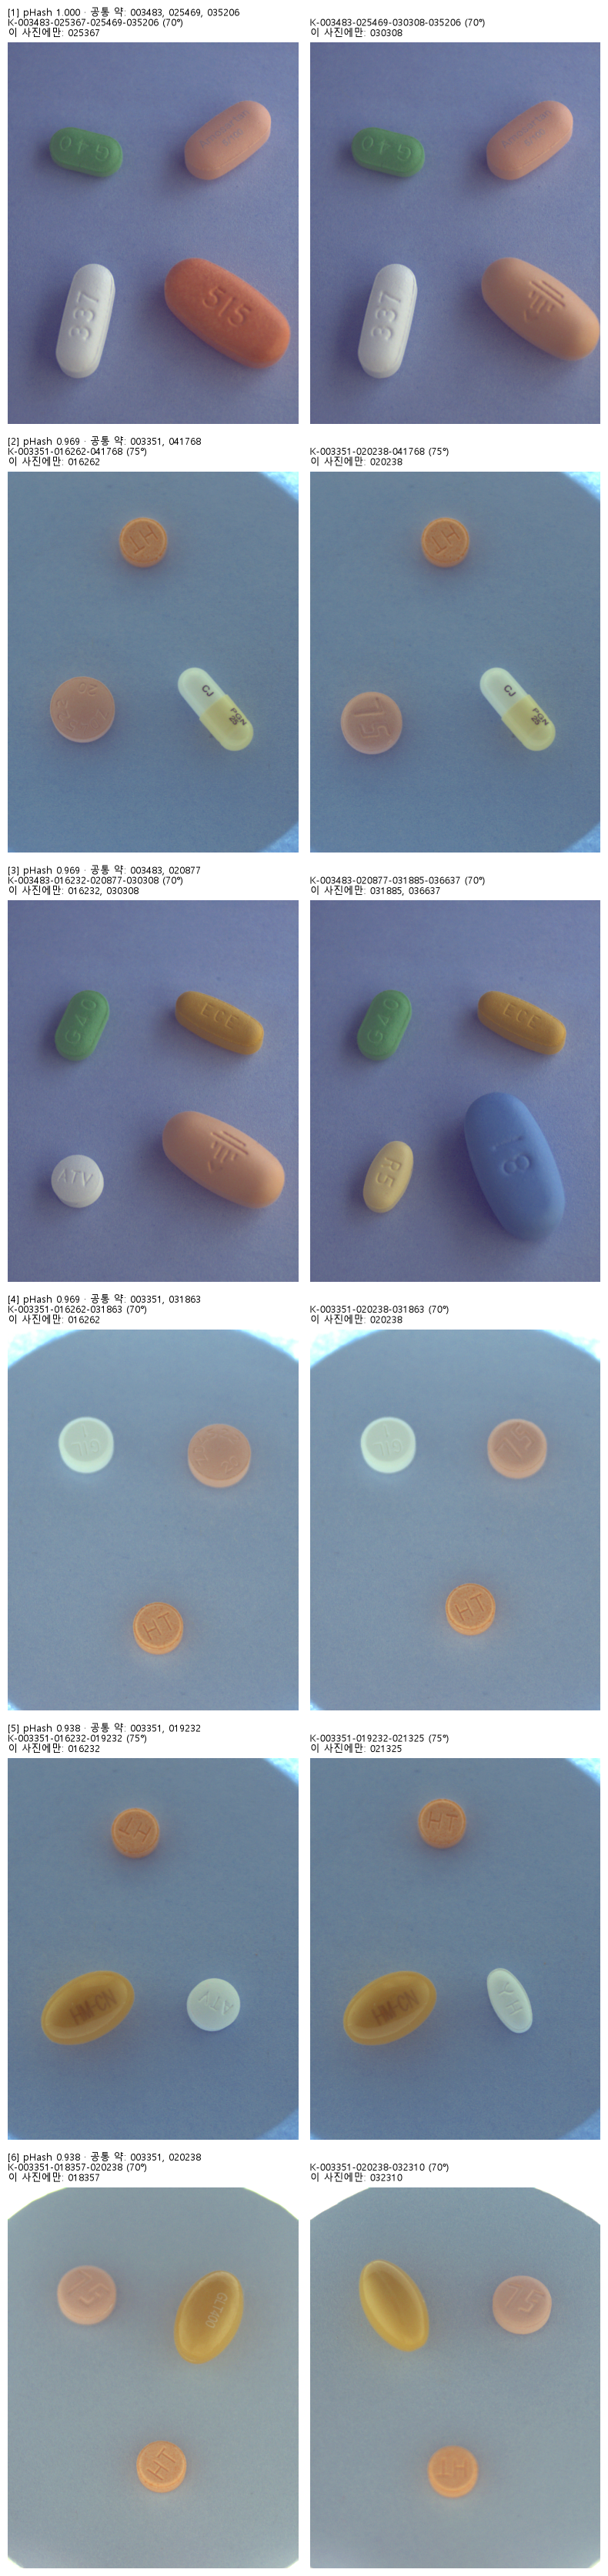

In [5]:
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# 한글 폰트 설정 (커널을 재시작해도 이 셀만으로 한글이 나오게 한다)
for font_file in ["malgun.ttf", "malgunbd.ttf"]:  # WSL: Windows 맑은 고딕 (보통, 굵게)
    path = Path("/mnt/c/Windows/Fonts") / font_file
    if path.exists():
        fm.fontManager.addfont(str(path))
installed = {f.name for f in fm.fontManager.ttflist}
plt.rcParams["font.family"] = next(
    (f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"] if f in installed), "sans-serif"
)
plt.rcParams["axes.unicode_minus"] = False

HIGH_SIM = 0.9  # 이 값 이상인 다른 조합 쌍을 본다
N_SHOW = 6

high = (phash_pairs[(phash_pairs["group"] == "다른 조합") & (phash_pairs["phash_sim"] >= HIGH_SIM)]
        .sort_values("phash_sim", ascending=False).reset_index(drop=True))
print(f"다른 조합 쌍 {int((phash_pairs['group'] == '다른 조합').sum())}개 중")
print(f"  pHash 1.000: {int((high['phash_sim'] == 1).sum())}쌍 / 0.95 이상: {int((high['phash_sim'] >= 0.95).sum())}쌍"
      f" / {HIGH_SIM} 이상: {len(high)}쌍")


def drug_codes(fn):
    """파일명 앞부분(K-003351-016262-041768)에서 약 코드 집합을 뽑는다."""
    return set(fn.split("_")[0].split("-")[1:])


fig, axes = plt.subplots(N_SHOW, 2, figsize=(8, 5.6 * N_SHOW), squeeze=False)
for i, ((ax1, ax2), r) in enumerate(zip(axes, high.head(N_SHOW).itertuples()), start=1):
    d1, d2 = drug_codes(r.file1), drug_codes(r.file2)
    ax1.imshow(plt.imread(TRAIN_IMG_DIR / r.file1)[::2, ::2])  # 절반 크기로 읽어 메모리를 아낀다
    ax2.imshow(plt.imread(TRAIN_IMG_DIR / r.file2)[::2, ::2])
    # 왼쪽 제목 첫 줄: 쌍 번호, pHash, 공통 약 / 아래 줄: 각 사진의 조합과 그 사진에만 있는 약
    ax1.set_title(f"[{i}] pHash {r.phash_sim:.3f} · 공통 약: {', '.join(sorted(d1 & d2))}\n"
                  f"{r.file1.split('_')[0]} ({r.file1.split('_')[5]}°)\n이 사진에만: {', '.join(sorted(d1 - d2))}",
                  fontsize=9, loc="left")
    ax2.set_title(f"\n{r.file2.split('_')[0]} ({r.file2.split('_')[5]}°)\n이 사진에만: {', '.join(sorted(d2 - d1))}",
                  fontsize=9, loc="left")
    ax1.axis("off")
    ax2.axis("off")
plt.tight_layout()
plt.show()


## 5단계 결과 해석: 다른 조합인데 pHash가 높은 쌍

다른 조합 쌍 26,638개 중 pHash 1.000은 1쌍, 0.95 이상은 4쌍, 0.9 이상은 62쌍이다. 상위 6쌍을 사진으로 확인했다.

| 쌍 | pHash | 같은 자리에 그대로 있는 약 | 바뀐 약 |
|---|---:|---|---|
| [1] | 1.000 | 3483, 25469, 35206 | 25367 → 30308 |
| [2] | 0.969 | 3351, 41768 | 16262 → 20238 |
| [3] | 0.969 | 3483, 20877 | 16232·30308 → 31885·36637 |
| [4] | 0.969 | 31863, 3351 | 16262 → 20238 |
| [5] | 0.938 | 3351, 19232 | 16232 → 21325 |
| [6] | 0.938 | 3351 | 위쪽 두 약의 좌우가 바뀌고 노란 타원이 18357 → 32310 |

**결론: 중복 사진도, pHash 오류도 아니다.** 같은 촬영 세팅에서 **일부 알약만 다른 약으로 바꿔 찍은** 사진이다. 그래서 조합 이름이 달라도 공통 약은 같은 자리, 같은 모습으로 여러 조합에 나온다.

**의미**

- **그룹 분할**: 같은 조합만 한쪽에 모아도, 세팅을 공유하는 다른 조합이 train과 validation으로 나뉘면 공통 약은 이미 본 모습 그대로다. **조합 단위 분할만으로는 누수가 남을 수 있다.**
- **헷갈리기 쉬운 약**: 바뀐 약끼리 서로 닮았다(16262 ↔ 20238 분홍 원형, 16232 ↔ 21325 흰 원형, 18357 ↔ 32310 노란 타원). 학습 후 혼동 행렬에서 확인할 후보다.


### 6단계: 정답 박스 위치로 "세팅 공유" 규모 세기

5단계에서 서로 다른 조합인데 공통 약이 같은 자리에 있는 사진을 찾았다. pHash는 이 데이터에서 둔하므로, 데이터 전체 규모는 정답 박스 위치로 센다.

- 서로 다른 조합이면서 같은 각도인 사진 쌍을 모두 비교한다.
- 공통 약의 박스 중심이 `SAME_DIST`(30px) 이내면 "같은 자리"다.
- 같은 자리인 공통 약이 `MIN_SAME`(2개) 이상이면 "세팅 공유"로 본다. 거의 모든 사진에 있는 3351 하나가 우연히 겹치는 경우를 거르기 위해서다.
- 세팅을 공유하는 조합끼리 이어서 "같은 촬영 세팅 묶음"을 만든다.


In [6]:
import itertools

import numpy as np

SAME_DIST = 30  # 박스 중심 거리가 이 px 이내면 같은 자리
MIN_SAME = 2  # 같은 자리인 공통 약이 이 개수 이상이면 세팅 공유

# 박스마다 조합, 각도, 중심 좌표
pos = ann_df[["file_name", "category_id", "x", "y", "w", "h"]].copy()
parts = pos["file_name"].str.split("_")
pos["combo"] = parts.str[0]
pos["angle"] = parts.str[5].astype(int)
pos["cx"] = pos["x"] + pos["w"] / 2
pos["cy"] = pos["y"] + pos["h"] / 2
# 사진마다 {약 코드: (cx, cy)}
centers = {fn: dict(zip(g["category_id"], zip(g["cx"], g["cy"]))) for fn, g in pos.groupby("file_name")}
img_info = pos.drop_duplicates("file_name").set_index("file_name")[["combo", "angle"]]

rows = []
for angle, g in img_info.groupby("angle"):
    for fn1, fn2 in itertools.combinations(g.index, 2):
        if g.at[fn1, "combo"] == g.at[fn2, "combo"]:
            continue
        shared = centers[fn1].keys() & centers[fn2].keys()
        if not shared:
            continue
        dists = [np.hypot(centers[fn1][c][0] - centers[fn2][c][0], centers[fn1][c][1] - centers[fn2][c][1]) for c in shared]
        rows.append({"angle": angle, "file1": fn1, "file2": fn2,
                     "combo1": g.at[fn1, "combo"], "combo2": g.at[fn2, "combo"],
                     "n_shared": len(shared), "n_same": sum(d <= SAME_DIST for d in dists)})
setup_pairs = pd.DataFrame(rows)
setup_pairs["setup_shared"] = setup_pairs["n_same"] >= MIN_SAME

print("다른 조합 + 같은 각도 + 공통 약이 있는 사진 쌍:", len(setup_pairs))
print(f"  공통 약 1개 이상이 같은 자리: {int((setup_pairs['n_same'] >= 1).sum())}쌍")
print(f"  공통 약 {MIN_SAME}개 이상이 같은 자리 (세팅 공유): {int(setup_pairs['setup_shared'].sum())}쌍")

# 세팅을 공유하는 조합끼리 이어서 묶음을 만든다 (서로 연결된 조합은 같은 묶음)
parent = {c: c for c in img_info["combo"].unique()}


def find(c):
    while parent[c] != c:
        parent[c] = parent[parent[c]]
        c = parent[c]
    return c


for c1, c2 in setup_pairs.loc[setup_pairs["setup_shared"], ["combo1", "combo2"]].values:
    parent[find(c1)] = find(c2)

combo_group = pd.Series({c: find(c) for c in parent}, name="setup_group")
group_sizes = combo_group.value_counts()
print(f"\n전체 조합 {len(combo_group)}개 → 촬영 세팅 묶음 {len(group_sizes)}개")
print("묶음 크기(묶음 안 조합 수)별 묶음 수:")
group_sizes.value_counts().sort_index().rename_axis("조합 수").rename("묶음 수")


다른 조합 + 같은 각도 + 공통 약이 있는 사진 쌍: 4560
  공통 약 1개 이상이 같은 자리: 1577쌍
  공통 약 2개 이상이 같은 자리 (세팅 공유): 103쌍

전체 조합 114개 → 촬영 세팅 묶음 67개
묶음 크기(묶음 안 조합 수)별 묶음 수:


조합 수
1     49
2     12
3      2
4      1
6      1
12     1
13     1
Name: 묶음 수, dtype: int64

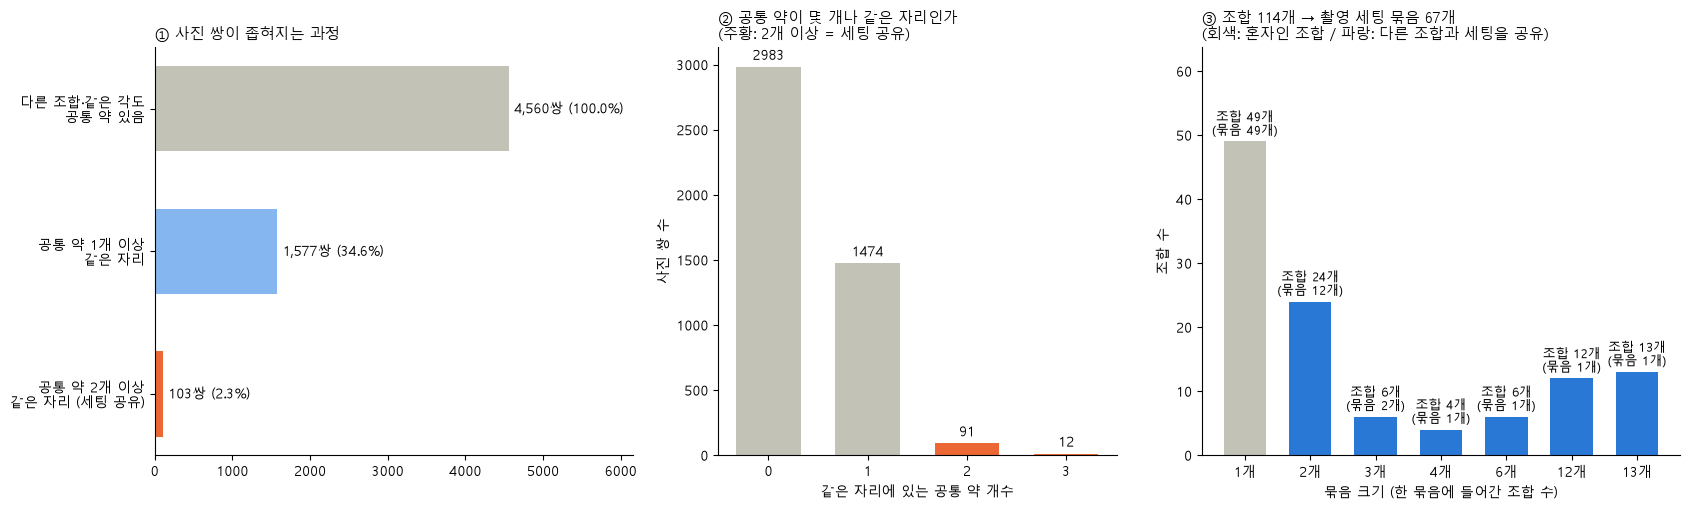

In [7]:
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# 한글 폰트 설정 (커널을 재시작해도 이 셀만으로 한글이 나오게 한다)
for font_file in ["malgun.ttf", "malgunbd.ttf"]:
    path = Path("/mnt/c/Windows/Fonts") / font_file
    if path.exists():
        fm.fontManager.addfont(str(path))
installed = {f.name for f in fm.fontManager.ttflist}
plt.rcParams["font.family"] = next(
    (f for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"] if f in installed), "sans-serif"
)

TEXT = "#52514e"
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.2, 1, 1.2]})

# ① 단계별로 좁혀지는 사진 쌍 수
ax = axes[0]
steps = ["다른 조합·같은 각도\n공통 약 있음", "공통 약 1개 이상\n같은 자리", f"공통 약 {MIN_SAME}개 이상\n같은 자리 (세팅 공유)"]
counts = [len(setup_pairs), int((setup_pairs["n_same"] >= 1).sum()), int(setup_pairs["setup_shared"].sum())]
bars = ax.barh(steps[::-1], counts[::-1], color=["#eb6834", "#86b6ef", "#c3c2b7"], height=0.6)
ax.bar_label(bars, labels=[f"{c:,}쌍 ({c / counts[0]:.1%})" for c in counts[::-1]], padding=4, fontsize=10)
ax.set_xlim(0, counts[0] * 1.35)
ax.set_title("① 사진 쌍이 좁혀지는 과정", loc="left", fontsize=11)

# ② 같은 자리인 공통 약 개수의 분포
ax = axes[1]
n_same_counts = setup_pairs["n_same"].value_counts().sort_index()
colors = ["#eb6834" if n >= MIN_SAME else "#c3c2b7" for n in n_same_counts.index]
bars = ax.bar(n_same_counts.index.astype(str), n_same_counts.values, color=colors, width=0.65)
ax.bar_label(bars, fmt="%d", padding=3, fontsize=10)
ax.set_xlabel("같은 자리에 있는 공통 약 개수")
ax.set_ylabel("사진 쌍 수")
ax.set_title(f"② 공통 약이 몇 개나 같은 자리인가\n(주황: {MIN_SAME}개 이상 = 세팅 공유)", loc="left", fontsize=11)

# ③ 조합 114개가 들어간 묶음의 크기
ax = axes[2]
combos_by_size = group_sizes.value_counts().sort_index()  # 묶음 크기 → 묶음 수
combos_in = combos_by_size.index * combos_by_size.values  # 묶음 크기 → 그 크기 묶음에 속한 조합 수
colors = ["#c3c2b7" if size == 1 else "#2a78d6" for size in combos_by_size.index]
bars = ax.bar([f"{s}개" for s in combos_by_size.index], combos_in, color=colors, width=0.65)
ax.bar_label(bars, labels=[f"조합 {c}개\n(묶음 {n}개)" for c, n in zip(combos_in, combos_by_size.values)],
             padding=3, fontsize=9)
ax.set_ylim(0, max(combos_in) * 1.3)
ax.set_xlabel("묶음 크기 (한 묶음에 들어간 조합 수)")
ax.set_ylabel("조합 수")
ax.set_title(f"③ 조합 {len(combo_group)}개 → 촬영 세팅 묶음 {len(group_sizes)}개\n"
             f"(회색: 혼자인 조합 / 파랑: 다른 조합과 세팅을 공유)", loc="left", fontsize=11)

for ax in axes:
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


## 한 줄 정의

- **조합** = 사진에 **어떤 약들이** 찍혀 있는가 (약 이름 목록)
- **세팅** = 그 약들을 판 위 **어디에 놓았는가** (알약의 배치 및 위치)

## 비유: 밥상

| | 밥상으로 치면 | 알약 사진으로 치면 |
|---|---|---|
| **조합** | 메뉴판 (밥, 국, 김치) | 약 이름 목록 (3351, 16262, 41768) |
| **세팅** | 상차림 (밥은 왼쪽, 국은 오른쪽 …) | 알약 배치 (3351은 위, 41768은 오른쪽 …) |

메뉴가 달라도 상차림은 그대로일 수 있습니다. 예를 들어 밥과 국은 그 자리에 두고 **김치만 깍두기로 바꾸면**, 메뉴는 달라졌지만 상차림은 거의 같습니다.

## 실제 사진으로 보면 (5단계의 [2]번 쌍)

```
   사진 A                           사진 B
   조합: 3351, 16262, 41768         조합: 3351, 20238, 41768

        [3351]                           [3351]          ← 같은 자리

   [16262]      [41768]            [20238]      [41768]  ← 41768도 같은 자리
     ↑                               ↑
   이 알약만 바꿔 놓고 다시 찍음
```

- **조합은 다릅니다.** 16262와 20238이 다르기 때문입니다. 그래서 파일 이름도 다릅니다.
- **세팅은 같습니다.** 3351과 41768을 그대로 두고 알약 **하나만 바꿔서** 다시 찍었기 때문입니다.

## 왜 이게 문제인가

train과 validation을 나눌 때 지금까지는 **조합(이름)**만 보고 나누려고 했습니다.

- 사진 A는 train에, 사진 B는 validation에 넣었다고 해 봅시다.
- 이름이 다르니 겉보기엔 다른 데이터 같습니다.
- 그런데 사진 B의 3351과 41768은 **사진 A에서 똑같은 자리, 똑같은 모습으로 이미 본 알약**입니다.
- 시험(validation)에 공부한 문제(train)가 그대로 나온 셈이라, 점수가 실제 실력보다 높게 나옵니다.

## 결과 숫자를 쉽게 말하면

- 조합(이름)으로 세면 114가지입니다.
- 그런데 같은 상차림(세팅)끼리 묶으면 **67가지**로 줄어듭니다.
- 즉 114개 조합 중 **65개는 다른 조합과 상차림을 공유**합니다. 알약 일부만 바꿔 찍은 형제 사진이 있다는 뜻입니다.

## 그래서 할 일

**같은 세팅(상차림)끼리는 train이든 validation이든 한쪽에 같이 넣습니다.** 이름(조합)만 보고 나누면 형제 사진이 양쪽으로 갈라져서, 모델 점수를 믿을 수 없게 됩니다.